In [112]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [113]:
df = pd.read_csv("../dataset/bank-additional-full.csv", sep=";")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

display(df.head())
display(df.tail())

Dataset loaded successfully!
Number of rows: 41188
Number of columns: 21
Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [114]:
print("Dataset information:")
df.info()

print("\nDataset columns:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["y"].value_counts())

print("\nTarget percentages:")
print(df["y"].value_counts(normalize=True) * 100)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188

In [115]:
# Create a working copy
df_clean = df.copy()

# Remove duplicate records
duplicate_count = df_clean.duplicated().sum()

print("Duplicate rows found:", duplicate_count)

df_clean = df_clean.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", df_clean.shape)

# Check missing values
print("\nTotal missing values:")
print(df_clean.isnull().sum().sum())

# Check unknown categorical values
print("\nUnknown values in categorical columns:")

for column in df_clean.select_dtypes(include=["object", "str"]).columns:
    unknown_count = (df_clean[column] == "unknown").sum()

    if unknown_count > 0:
        print(column, ":", unknown_count)

# Understand pdays = 999
print("\nPdays distribution:")
print(df_clean["pdays"].value_counts().sort_index())

never_contacted = (df_clean["pdays"] == 999).sum()

print("\nCustomers never previously contacted:", never_contacted)
print(
    "Percentage:",
    round(never_contacted / len(df_clean) * 100, 2),
    "%"
)

Duplicate rows found: 12
Dataset shape after removing duplicates: (41176, 21)

Total missing values:
0

Unknown values in categorical columns:
job : 330
marital : 80
education : 1730
default : 8596
housing : 990
loan : 990

Pdays distribution:
pdays
0         15
1         26
2         61
3        439
4        118
5         46
6        412
7         60
8         18
9         64
10        52
11        28
12        58
13        36
14        20
15        24
16        11
17         8
18         7
19         3
20         1
21         2
22         3
25         1
26         1
27         1
999    39661
Name: count, dtype: int64

Customers never previously contacted: 39661
Percentage: 96.32 %


In [116]:
# Create numerical target for EDA
df_clean["target"] = df_clean["y"].map({
    "no": 0,
    "yes": 1
})

print(df_clean[["y", "target"]].head())

    y  target
0  no       0
1  no       0
2  no       0
3  no       0
4  no       0


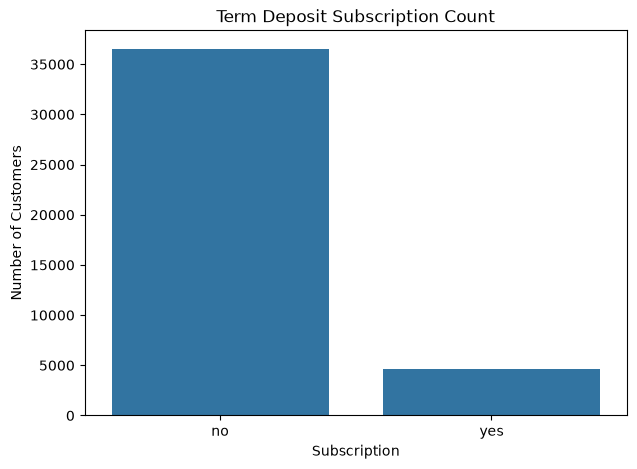

The dataset is imbalanced, with approximately 88.73% non-subscribers and 11.27% subscribers.


In [117]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="y")

plt.title("Term Deposit Subscription Count")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

plt.show()

print(
    "The dataset is imbalanced, with approximately 88.73% "
    "non-subscribers and 11.27% subscribers."
)

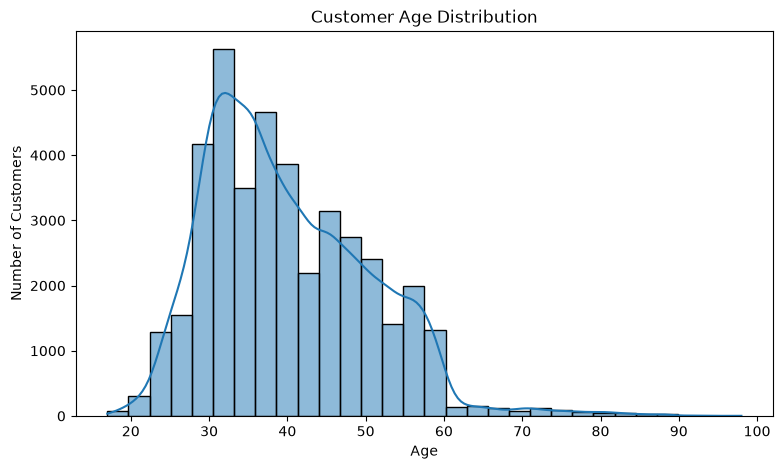

Dataset loaded successfully!
Number of rows: 41188
Number of columns: 21
Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [118]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="age",
    bins=30,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()
df = pd.read_csv("../dataset/bank-additional-full.csv", sep=";")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

display(df.head())
display(df.tail())

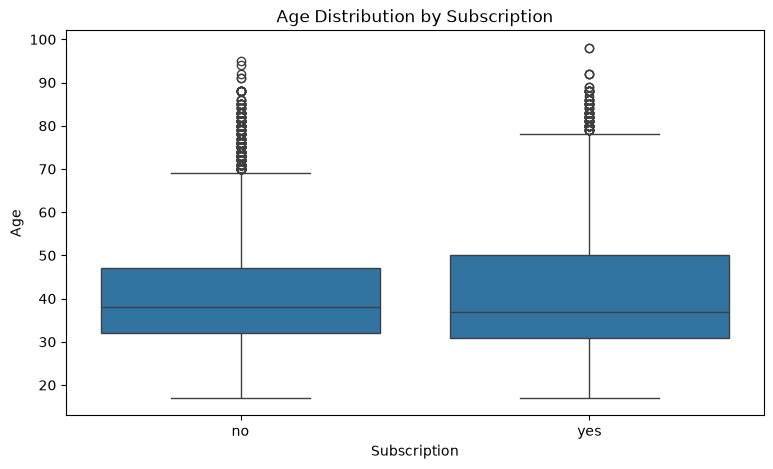

In [119]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x="y",
    y="age"
)

plt.title("Age Distribution by Subscription")
plt.xlabel("Subscription")
plt.ylabel("Age")

plt.show()

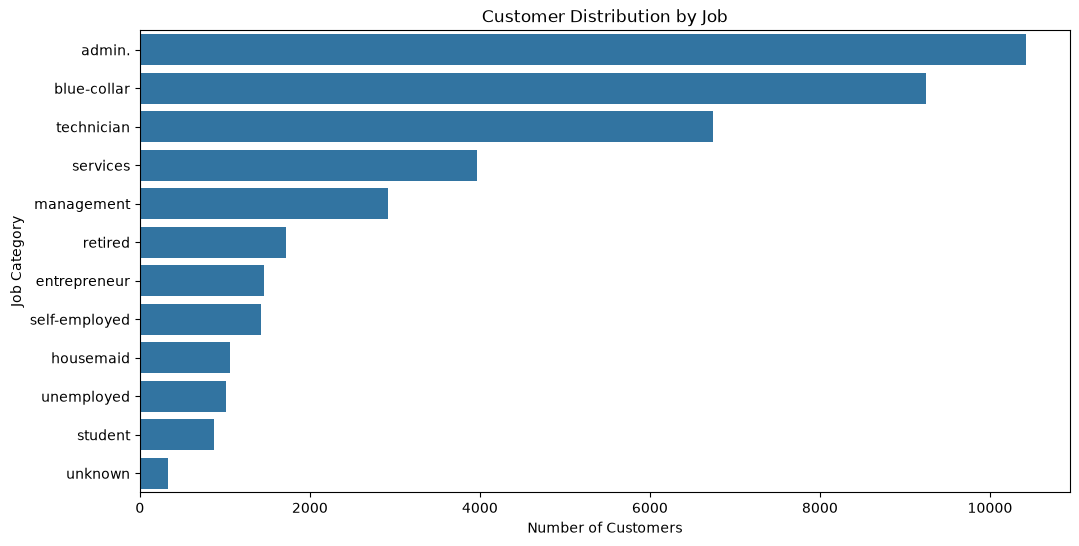

In [120]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_clean,
    y="job",
    order=df_clean["job"].value_counts().index
)

plt.title("Customer Distribution by Job")
plt.xlabel("Number of Customers")
plt.ylabel("Job Category")

plt.show()

job
student          31.428571
retired          25.261932
unemployed       14.201183
admin.           12.966695
management       11.217510
unknown          11.212121
technician       10.832468
self-employed    10.485574
housemaid        10.000000
entrepreneur      8.516484
services          8.142173
blue-collar       6.895061
Name: target, dtype: float64


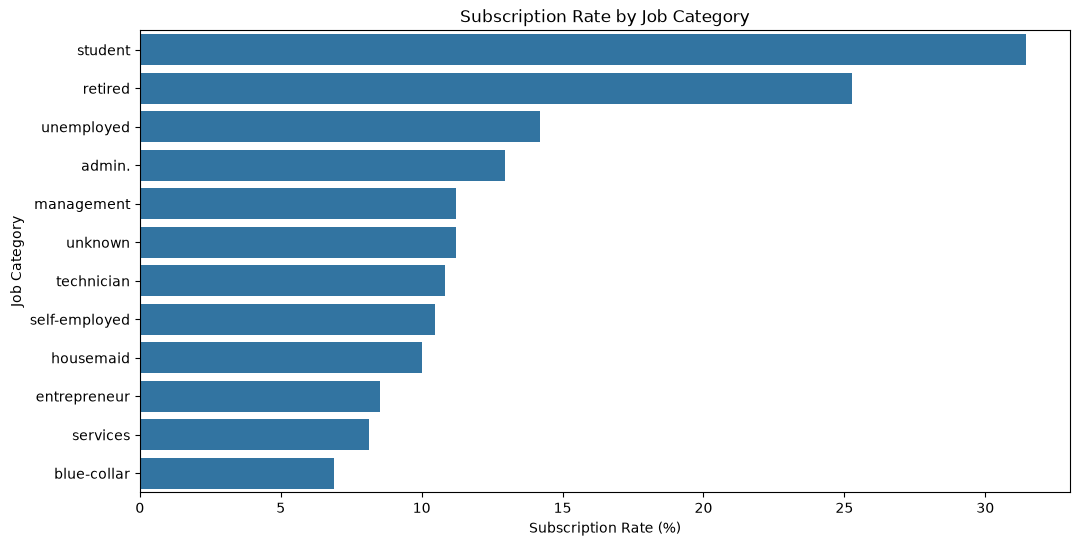

In [121]:
job_subscription = (
    df_clean.groupby("job")["target"]
    .mean()
    .sort_values(ascending=False) * 100
)

print(job_subscription)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=job_subscription.values,
    y=job_subscription.index
)

plt.title("Subscription Rate by Job Category")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job Category")

plt.show()

marital
divorced    10.323140
married     10.156093
single      14.008993
unknown     15.000000
Name: target, dtype: float64


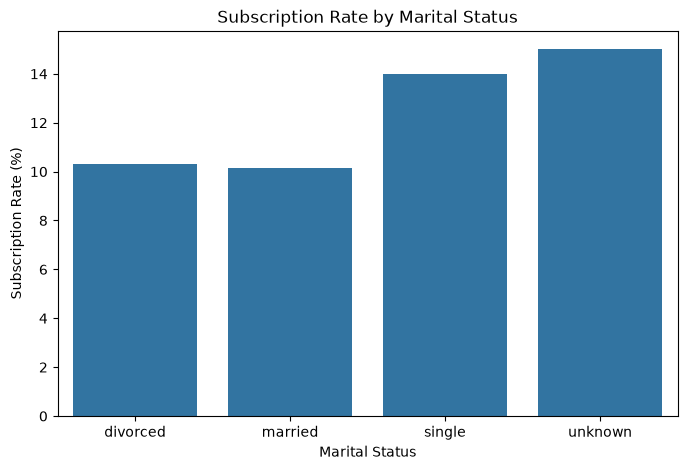

In [122]:
marital_subscription = (
    df_clean.groupby("marital")["target"].mean() * 100
)

print(marital_subscription)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=marital_subscription.index,
    y=marital_subscription.values
)

plt.title("Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")

plt.show()

education
illiterate             22.222222
unknown                14.508671
university.degree      13.720816
professional.course    11.354962
high.school            10.838940
basic.4y               10.249042
basic.6y                8.206024
basic.9y                7.824648
Name: target, dtype: float64


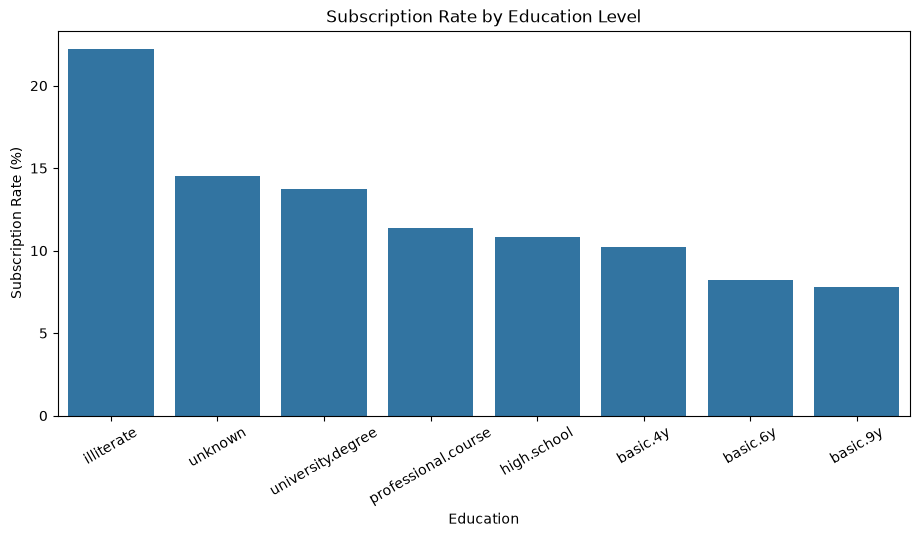

In [123]:
education_subscription = (
    df_clean.groupby("education")["target"]
    .mean()
    .sort_values(ascending=False) * 100
)

print(education_subscription)

plt.figure(figsize=(11, 5))

sns.barplot(
    x=education_subscription.index,
    y=education_subscription.values
)

plt.title("Subscription Rate by Education Level")
plt.xlabel("Education")
plt.ylabel("Subscription Rate (%)")

plt.xticks(rotation=30)

plt.show()

poutcome
failure        14.228598
nonexistent     8.832382
success        65.112891
Name: target, dtype: float64


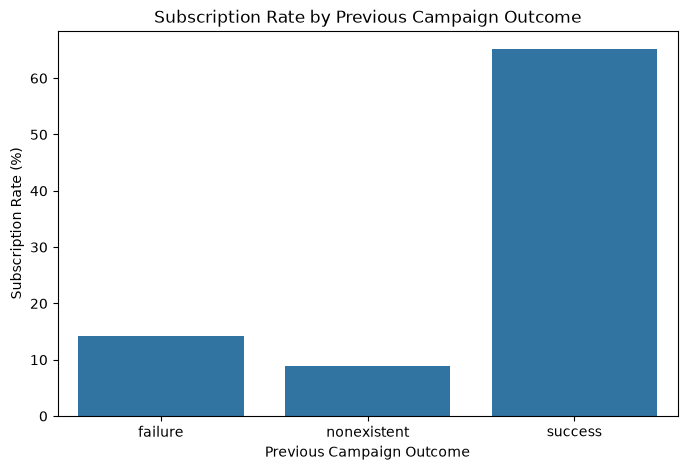

In [124]:
poutcome_subscription = (
    df_clean.groupby("poutcome")["target"].mean() * 100
)

print(poutcome_subscription)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=poutcome_subscription.index,
    y=poutcome_subscription.values
)

plt.title("Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")

plt.show()

In [125]:
# Whether the customer was previously contacted
df_clean["previously_contacted"] = np.where(
    df_clean["pdays"] == 999,
    0,
    1
)

print(
    df_clean[
        ["pdays", "previously_contacted"]
    ].head(10)
)

print(df_clean["previously_contacted"].value_counts())

   pdays  previously_contacted
0    999                     0
1    999                     0
2    999                     0
3    999                     0
4    999                     0
5    999                     0
6    999                     0
7    999                     0
8    999                     0
9    999                     0
previously_contacted
0    39661
1     1515
Name: count, dtype: int64


In [126]:
# Whether the customer had previous campaign contacts
df_clean["previous_campaign_contacted"] = np.where(
    df_clean["previous"] > 0,
    1,
    0
)

print(
    df_clean[
        ["previous", "previous_campaign_contacted"]
    ].head(10)
)

print(df_clean["previous_campaign_contacted"].value_counts())

   previous  previous_campaign_contacted
0         0                            0
1         0                            0
2         0                            0
3         0                            0
4         0                            0
5         0                            0
6         0                            0
7         0                            0
8         0                            0
9         0                            0
previous_campaign_contacted
0    35551
1     5625
Name: count, dtype: int64


In [127]:
# Create age groups
age_bins = [0, 24, 35, 50, 65, np.inf]

age_labels = [
    "Young",
    "Young Adult",
    "Adult",
    "Senior",
    "Elderly"
]

df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=age_bins,
    labels=age_labels
)

print(df_clean[["age", "age_group"]].head(10))
print(df_clean["age_group"].value_counts().sort_index())

   age    age_group
0   56       Senior
1   57       Senior
2   37        Adult
3   40        Adult
4   56       Senior
5   45        Adult
6   59       Senior
7   41        Adult
8   24        Young
9   25  Young Adult
age_group
Young           1067
Young Adult    15442
Adult          17489
Senior          6560
Elderly          618
Name: count, dtype: int64


In [128]:
# Create campaign frequency categories for EDA
campaign_bins = [0, 1, 3, np.inf]

campaign_labels = [
    "First Contact",
    "Moderate Contact",
    "Frequent Contact"
]

df_clean["campaign_frequency"] = pd.cut(
    df_clean["campaign"],
    bins=campaign_bins,
    labels=campaign_labels
)

print(
    df_clean[
        ["campaign", "campaign_frequency"]
    ].head(10)
)

print(df_clean["campaign_frequency"].value_counts())

   campaign campaign_frequency
0         1      First Contact
1         1      First Contact
2         1      First Contact
3         1      First Contact
4         1      First Contact
5         1      First Contact
6         1      First Contact
7         1      First Contact
8         1      First Contact
9         1      First Contact
campaign_frequency
First Contact       17634
Moderate Contact    15908
Frequent Contact     7634
Name: count, dtype: int64


In [129]:
new_features = [
    "previously_contacted",
    "previous_campaign_contacted",
    "age_group",
    "campaign_frequency"
]

print("Newly created features:")
display(df_clean[new_features].head(10))

print("Updated dataset shape:", df_clean.shape)

Newly created features:


,previously_contacted,previous_campaign_contacted,age_group,campaign_frequency
0,0,0,Senior,First Contact
1,0,0,Senior,First Contact
2,0,0,Adult,First Contact
3,0,0,Adult,First Contact
4,0,0,Senior,First Contact
5,0,0,Adult,First Contact
6,0,0,Senior,First Contact
7,0,0,Adult,First Contact
8,0,0,Young,First Contact
9,0,0,Young Adult,First Contact


Updated dataset shape: (41176, 26)


In [130]:
# Separate target
y = df_clean["y"].map({
    "no": 0,
    "yes": 1
})

# Exclude target and information unavailable before the call
columns_to_drop = [
    "y",
    "target",
    "duration",
    "campaign",
    "campaign_frequency"
]

X = df_clean.drop(
    columns=columns_to_drop,
    errors="ignore"
)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFeature columns:")
print(X.columns.tolist())

assert "y" not in X.columns
assert "target" not in X.columns
assert "duration" not in X.columns
assert "campaign" not in X.columns
assert "campaign_frequency" not in X.columns

print("\nFeature leakage checks passed!")

Features shape: (41176, 21)
Target shape: (41176,)

Target distribution:
y
0    36537
1     4639
Name: count, dtype: int64

Feature columns:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'previous_campaign_contacted', 'age_group']

Feature leakage checks passed!


In [131]:
from sklearn.model_selection import train_test_split

# Separate final test data
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Separate training and validation data
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.1764705882,
    random_state=42,
    stratify=y_train_full
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (28822, 21)
Validation features: (6177, 21)
Testing features: (6177, 21)

Training target distribution:
y
0    0.887343
1    0.112657
Name: proportion, dtype: float64

Validation target distribution:
y
0    0.887324
1    0.112676
Name: proportion, dtype: float64

Testing target distribution:
y
0    0.887324
1    0.112676
Name: proportion, dtype: float64


In [132]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical features
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

# Identify categorical features
categorical_features = [
    column for column in X_train.columns
    if column not in numeric_features
]

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['age', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'previous_campaign_contacted']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'age_group']

Number of numerical features: 10
Number of categorical features: 11


In [133]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [134]:
# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and testing data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Validation data after preprocessing:", X_val_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (28822, 68)
Validation data after preprocessing: (6177, 68)
Testing data after preprocessing: (6177, 68)


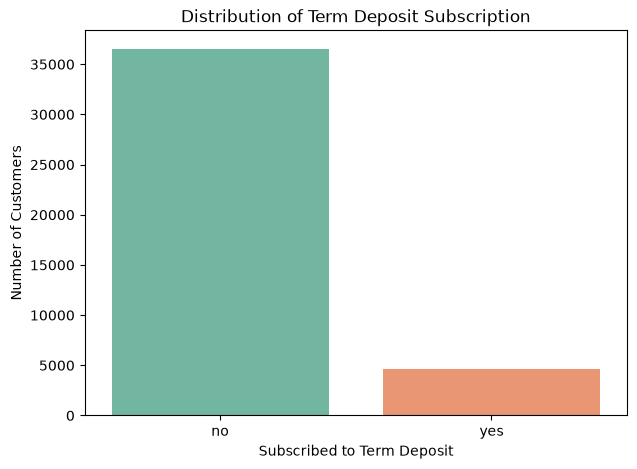

Target distribution:
y
no     36537
yes     4639
Name: count, dtype: int64

Target percentage:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64
Target distribution
 Most customers did not subscribe.
 Only a much smaller group subscribed.
 This confirms that our dataset is imbalanced. We should consider this when training and evaluating models.


In [135]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="y",
    hue="y",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Term Deposit Subscription")
plt.xlabel("Subscribed to Term Deposit")
plt.ylabel("Number of Customers")
plt.show()

print("Target distribution:")
print(df_clean["y"].value_counts())

print("\nTarget percentage:")
print(
    (df_clean["y"].value_counts(normalize=True) * 100).round(2)
)
print("Target distribution\n Most customers did not subscribe.\n Only a much smaller group subscribed.\n This confirms that our dataset is imbalanced. We should consider this when training and evaluating models.")

Customer age distribution
Most customers are approximately 30–50 years old.
There are fewer customers above 60.
 The age distribution is right-skewed, with a smaller number of older customers.


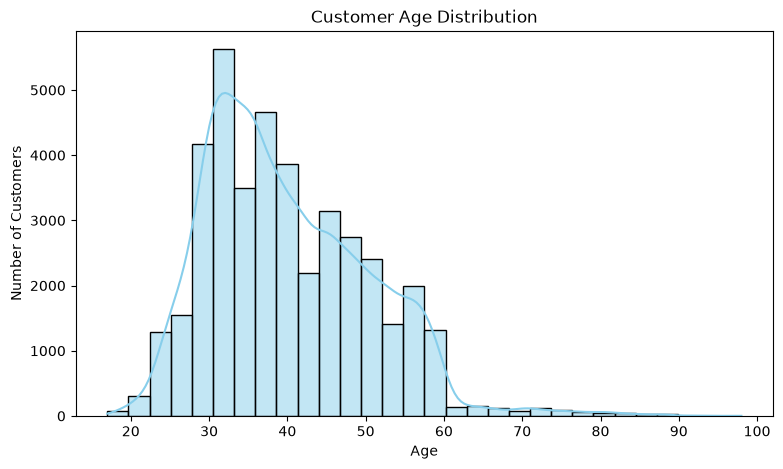

In [136]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="age",
    bins=30,
    kde=True,
    color="skyblue"
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
print("Customer age distribution\nMost customers are approximately 30–50 years old.\nThere are fewer customers above 60.\n The age distribution is right-skewed, with a smaller number of older customers.")
plt.show()

Subscription by age group
Young Adult and Adult groups contain the largest number of customers.
Elderly customers appear to have a relatively high number of subscriptions compared with their group size.
We should calculate subscription percentages before concluding which group responds best.


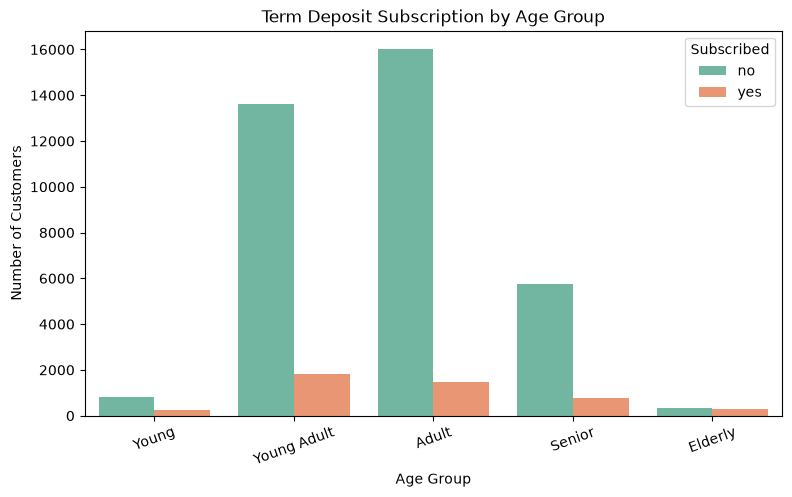

In [137]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x="age_group",
    hue="y",
    palette="Set2"
)

plt.title("Term Deposit Subscription by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.legend(title="Subscribed")
print("Subscription by age group\nYoung Adult and Adult groups contain the largest number of customers.\nElderly customers appear to have a relatively high number of subscriptions compared with their group size.\nWe should calculate subscription percentages before concluding which group responds best.")
plt.show()

Subscription by job
Admin, blue-collar, and technician categories contain many customers.
The number of subscriptions varies across job categories.
Customer counts alone do not tell us which job has the highest subscription rate.


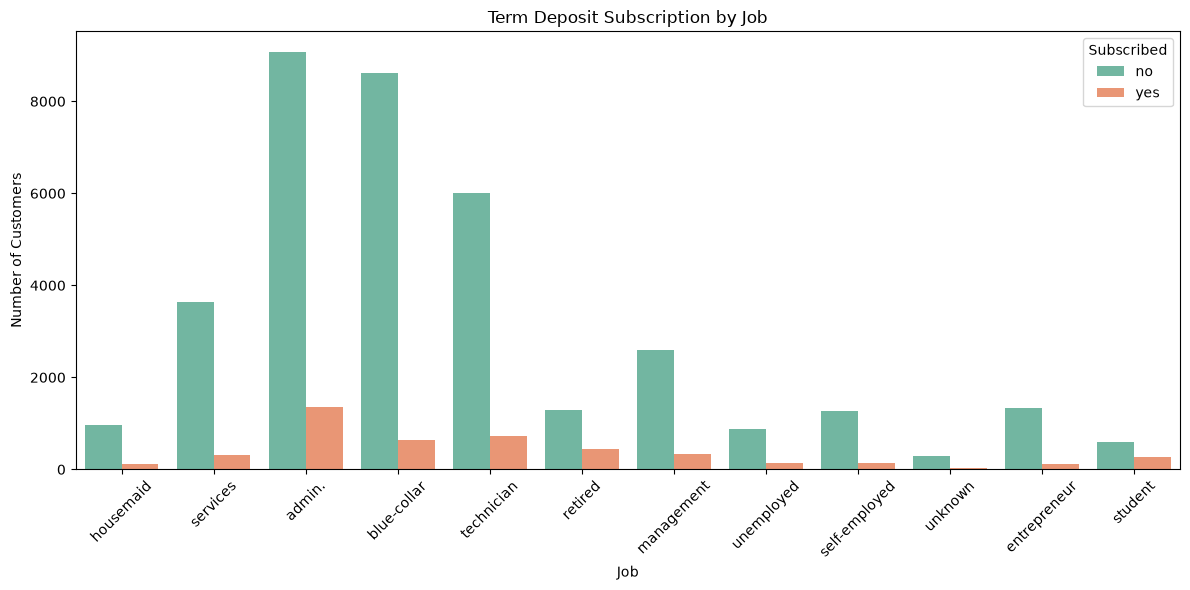

In [138]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_clean,
    x="job",
    hue="y",
    palette="Set2"
)

plt.title("Term Deposit Subscription by Job")
plt.xlabel("Job")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.legend(title="Subscribed")
plt.tight_layout()
print("Subscription by job\nAdmin, blue-collar, and technician categories contain many customers.\nThe number of subscriptions varies across job categories.\nCustomer counts alone do not tell us which job has the highest subscription rate.")
plt.show()

Subscription by marital status
Married customers form the largest group.
Single customers also contribute a noticeable number of subscriptions.


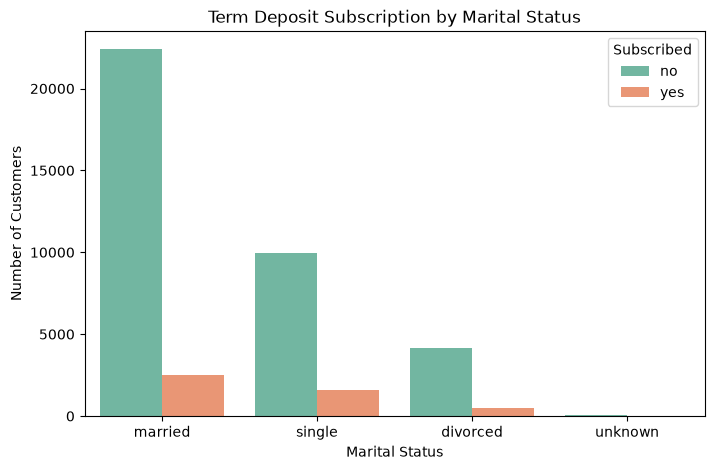

In [139]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="marital",
    hue="y",
    palette="Set2"
)

plt.title("Term Deposit Subscription by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Number of Customers")
plt.legend(title="Subscribed")
print("Subscription by marital status\nMarried customers form the largest group.\nSingle customers also contribute a noticeable number of subscriptions.")
plt.show()

Subscription by education
University-degree and high-school customers form large groups.
Both contribute a substantial number of subscriptions.


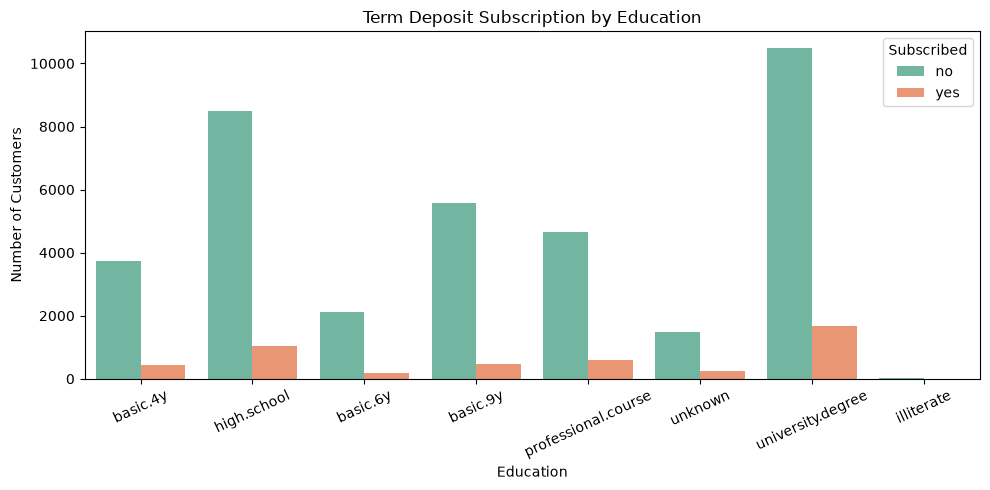

In [140]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x="education",
    hue="y",
    palette="Set2"
)

plt.title("Term Deposit Subscription by Education")
plt.xlabel("Education")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25)
plt.legend(title="Subscribed")
plt.tight_layout()
print("Subscription by education\nUniversity-degree and high-school customers form large groups.\nBoth contribute a substantial number of subscriptions.")
plt.show()

Previous campaign outcome
Customers with a previous successful campaign outcome show a strong subscription pattern.
This may be an important predictor for our machine-learning models.


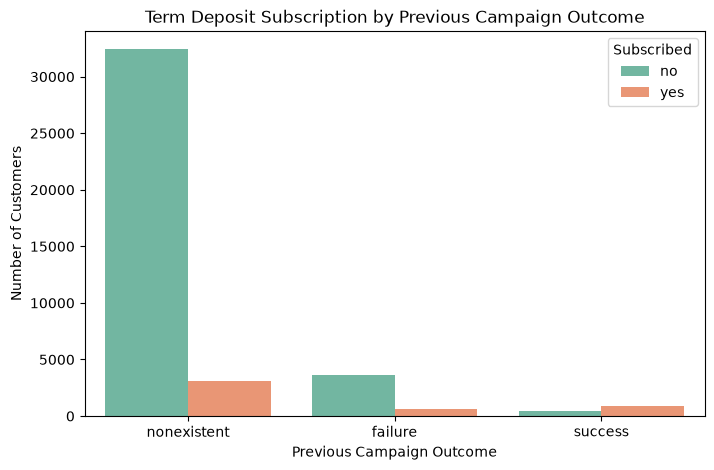

In [141]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="poutcome",
    hue="y",
    palette="Set2"
)

plt.title("Term Deposit Subscription by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Number of Customers")
plt.legend(title="Subscribed")
print("Previous campaign outcome\nCustomers with a previous successful campaign outcome show a strong subscription pattern.\nThis may be an important predictor for our machine-learning models.")
plt.show()

In [142]:
# Subscription rate by age group
age_response_rate = (
    df_clean.groupby("age_group", observed=True)["target"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

print("Subscription Rate by Age Group (%):")
print(age_response_rate)


# Subscription rate by job
job_response_rate = (
    df_clean.groupby("job")["target"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

print("\nSubscription Rate by Job (%):")
print(job_response_rate)


# Subscription rate by marital status
marital_response_rate = (
    df_clean.groupby("marital")["target"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

print("\nSubscription Rate by Marital Status (%):")
print(marital_response_rate)


# Subscription rate by education
education_response_rate = (
    df_clean.groupby("education")["target"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

print("\nSubscription Rate by Education (%):")
print(education_response_rate)


# Subscription rate by previous campaign outcome
poutcome_response_rate = (
    df_clean.groupby("poutcome")["target"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

print("\nSubscription Rate by Previous Campaign Outcome (%):")
print(poutcome_response_rate)

Subscription Rate by Age Group (%):
age_group
Elderly        46.93
Young          23.99
Senior         12.07
Young Adult    11.87
Adult           8.39
Name: target, dtype: float64

Subscription Rate by Job (%):
job
student          31.43
retired          25.26
unemployed       14.20
admin.           12.97
management       11.22
unknown          11.21
technician       10.83
self-employed    10.49
housemaid        10.00
entrepreneur      8.52
services          8.14
blue-collar       6.90
Name: target, dtype: float64

Subscription Rate by Marital Status (%):
marital
unknown     15.00
single      14.01
divorced    10.32
married     10.16
Name: target, dtype: float64

Subscription Rate by Education (%):
education
illiterate             22.22
unknown                14.51
university.degree      13.72
professional.course    11.35
high.school            10.84
basic.4y               10.25
basic.6y                8.21
basic.9y                7.82
Name: target, dtype: float64

Subscription Rate by

In [143]:
print("Existing engineered columns:")

engineered_columns = [
    "previously_contacted",
    "previous_campaign_contacted",
    "age_group",
    "campaign_frequency"
]

for column in engineered_columns:
    print(column, ":", column in df_clean.columns)

Existing engineered columns:
previously_contacted : True
previous_campaign_contacted : True
age_group : True
campaign_frequency : True


In [144]:
# Separate target variable
y = df_clean["y"].map({
    "no": 0,
    "yes": 1
})

# Columns that should not be used as prediction features
columns_to_drop = [
    "y",
    "target",
    "duration",
    "campaign",
    "campaign_frequency"
]

# Create feature dataset
X = df_clean.drop(
    columns=columns_to_drop,
    errors="ignore"
)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFeature columns:")
print(X.columns.tolist())

# Check for target leakage
assert "y" not in X.columns
assert "target" not in X.columns
assert "duration" not in X.columns
assert "campaign" not in X.columns
assert "campaign_frequency" not in X.columns

print("\nTarget leakage checks passed!")

Features shape: (41176, 21)
Target shape: (41176,)

Target distribution:
y
0    36537
1     4639
Name: count, dtype: int64

Feature columns:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'previous_campaign_contacted', 'age_group']

Target leakage checks passed!


In [145]:
from sklearn.model_selection import train_test_split

# First, separate the test dataset (15%)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Split the remaining data into training (70%) and validation (15%)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.1764705882,
    random_state=42,
    stratify=y_train_full
)

# Display dataset shapes
print("Training dataset:", X_train.shape, y_train.shape)
print("Validation dataset:", X_val.shape, y_val.shape)
print("Testing dataset:", X_test.shape, y_test.shape)

# Check target distribution in each dataset
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True).round(4))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(4))

Training dataset: (28822, 21) (28822,)
Validation dataset: (6177, 21) (6177,)
Testing dataset: (6177, 21) (6177,)

Training target distribution:
y
0    0.8873
1    0.1127
Name: proportion, dtype: float64

Validation target distribution:
y
0    0.8873
1    0.1127
Name: proportion, dtype: float64

Testing target distribution:
y
0    0.8873
1    0.1127
Name: proportion, dtype: float64


In [146]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nNumber of numerical features:", len(numeric_features))

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of categorical features:", len(categorical_features))

Numerical features:
['age', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'previous_campaign_contacted']

Number of numerical features: 10

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'age_group']

Number of categorical features: 11


In [147]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [148]:
# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and testing data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)
print("Validation processed shape:", X_val_processed.shape)
print("Testing processed shape:", X_test_processed.shape)

Training processed shape: (28822, 68)
Validation processed shape: (6177, 68)
Testing processed shape: (6177, 68)


In [149]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

In [150]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("Initial models defined:")
for name in models:
    print(name)

Initial models defined:
Logistic Regression
Decision Tree
Random Forest
Gradient Boosting


In [151]:
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train_processed, y_train)

    trained_models[name] = model

print("\nFour initial models trained successfully!")

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...

Four initial models trained successfully!


In [152]:
svm_model = CalibratedClassifierCV(
    LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=3000
    ),
    cv=3
)

print("Training Support Vector Machine...")

svm_model.fit(X_train_processed, y_train)

trained_models["Support Vector Machine"] = svm_model

print("\nAll five initial models trained successfully!")

Training Support Vector Machine...

All five initial models trained successfully!


In [153]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

import pandas as pd

In [154]:
model_results = []

for model_name, model in trained_models.items():

    # Predict customer subscription
    y_pred = model.predict(X_val_processed)

    # Predict subscription probabilities
    y_prob = model.predict_proba(X_val_processed)[:, 1]

    # Calculate evaluation metrics
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1-Score": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_prob),
        "PR-AUC": average_precision_score(y_val, y_prob)
    }

    model_results.append(results)

    print(f"{model_name} evaluated successfully!")

Logistic Regression evaluated successfully!
Decision Tree evaluated successfully!
Random Forest evaluated successfully!
Gradient Boosting evaluated successfully!
Support Vector Machine evaluated successfully!


In [155]:
model_comparison = pd.DataFrame(model_results)

model_comparison = model_comparison.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

print("\nInitial Model Comparison:")
display(model_comparison.round(4))


Initial Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Gradient Boosting,0.9014,0.6593,0.2586,0.3715,0.7935,0.4717
1,Logistic Regression,0.8300,0.3556,0.6264,0.4537,0.7865,0.4406
2,Support Vector Machine,0.8995,0.6569,0.2256,0.3358,0.7864,0.4363
3,Random Forest,0.8674,0.4200,0.4641,0.4410,0.7661,0.3371
4,Decision Tree,0.8384,0.3029,0.3333,0.3174,0.6193,0.1825


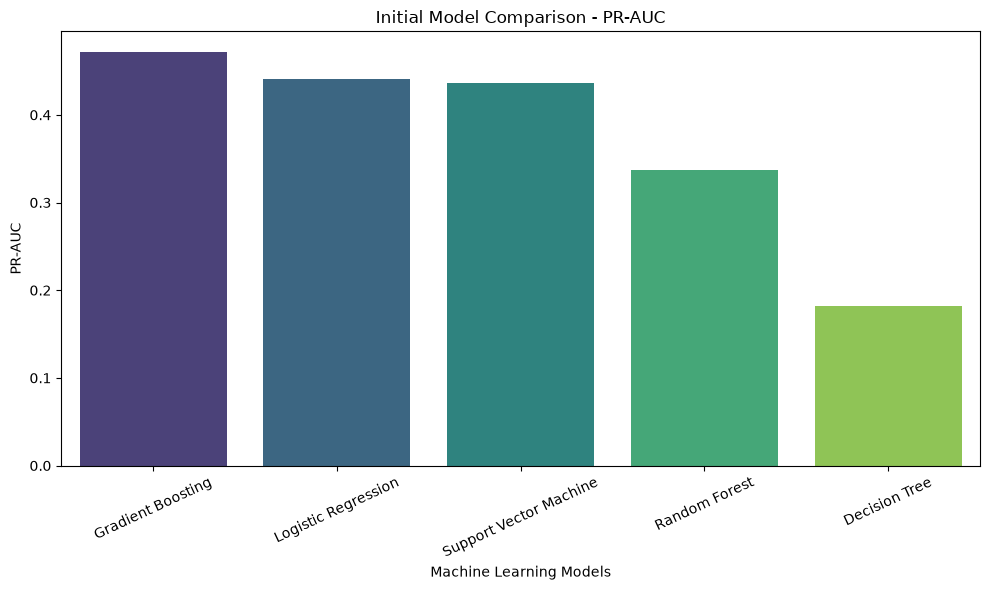

In [156]:
# Compare model performance using PR-AUC
plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="PR-AUC",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title("Initial Model Comparison - PR-AUC")
plt.xlabel("Machine Learning Models")
plt.ylabel("PR-AUC")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

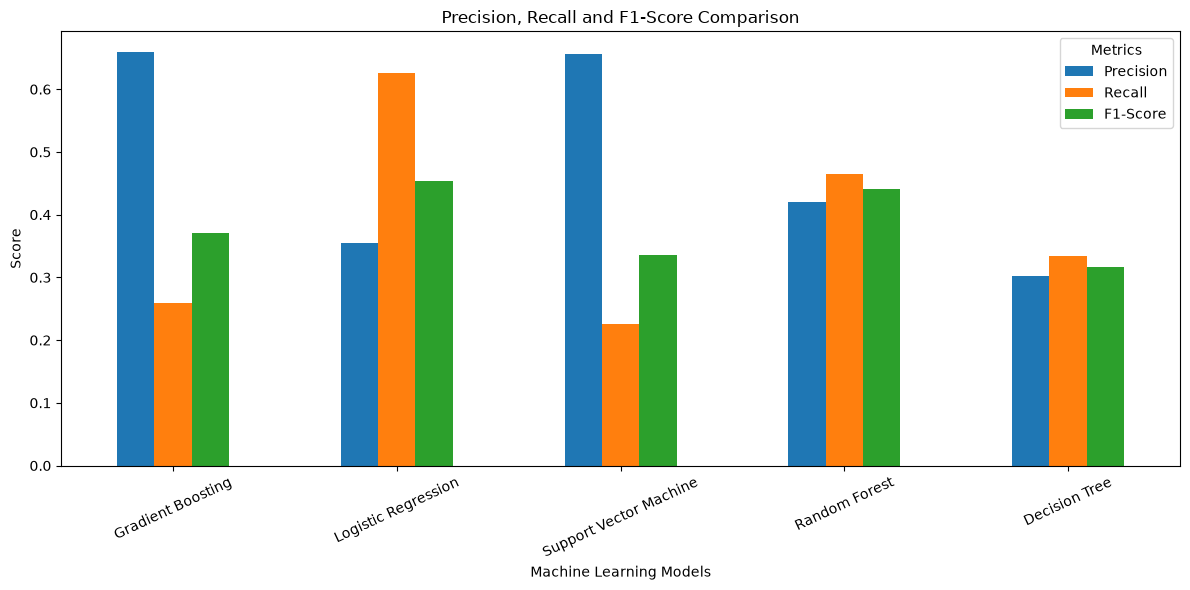

In [157]:
metrics_to_plot = ["Precision", "Recall", "F1-Score"]

model_comparison.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Precision, Recall and F1-Score Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=25)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

In [158]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

In [159]:
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

In [160]:
logistic_params = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

In [161]:
logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_params,
    scoring="average_precision",
    cv=3,
    n_jobs=-1,
    verbose=1
)

logistic_grid.fit(X_train, y_train)

print("Best Logistic Regression Parameters:")
print(logistic_grid.best_params_)

print("\nBest Logistic Regression Cross-Validation PR-AUC:")
print(logistic_grid.best_score_)

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best Logistic Regression Parameters:
{'model__C': 100}

Best Logistic Regression Cross-Validation PR-AUC:
0.44772600238480936


In [162]:
gradient_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(
        random_state=42
    ))
])

In [163]:
gradient_params = {
    "model__n_estimators": [100, 150],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3]
}

In [164]:
gradient_grid = GridSearchCV(
    estimator=gradient_pipeline,
    param_grid=gradient_params,
    scoring="average_precision",
    cv=3,
    n_jobs=-1,
    verbose=1
)

gradient_grid.fit(X_train, y_train)

print("Best Gradient Boosting Parameters:")
print(gradient_grid.best_params_)

print("\nBest Gradient Boosting Cross-Validation PR-AUC:")
print(gradient_grid.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Gradient Boosting Parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 150}

Best Gradient Boosting Cross-Validation PR-AUC:
0.4615816078365185


In [165]:
best_logistic_model = logistic_grid.best_estimator_
best_gradient_model = gradient_grid.best_estimator_

print("Both tuned models saved successfully!")

Both tuned models saved successfully!


In [166]:
# Store tuned models
tuned_models = {
    "Tuned Logistic Regression": best_logistic_model,
    "Tuned Gradient Boosting": best_gradient_model
}

# Evaluate tuned models on validation data
tuned_results = []

for model_name, model in tuned_models.items():

    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1-Score": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_prob),
        "PR-AUC": average_precision_score(y_val, y_prob)
    }

    tuned_results.append(results)

# Create comparison table
tuned_comparison = pd.DataFrame(tuned_results)

print("Tuned Model Results:")
display(tuned_comparison.round(4))

Tuned Model Results:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Tuned Logistic Regression,0.8303,0.3560,0.6250,0.4536,0.7865,0.4409
1,Tuned Gradient Boosting,0.9009,0.6615,0.2471,0.3598,0.7932,0.4693


In [167]:
# Combine initial and tuned model results
all_model_comparison = pd.concat(
    [model_comparison, tuned_comparison],
    ignore_index=True
)

# Sort by PR-AUC
all_model_comparison = all_model_comparison.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

print("Complete Model Comparison:")
display(all_model_comparison.round(4))

Complete Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Gradient Boosting,0.9014,0.6593,0.2586,0.3715,0.7935,0.4717
1,Tuned Gradient Boosting,0.9009,0.6615,0.2471,0.3598,0.7932,0.4693
2,Tuned Logistic Regression,0.8303,0.3560,0.6250,0.4536,0.7865,0.4409
3,Logistic Regression,0.8300,0.3556,0.6264,0.4537,0.7865,0.4406
4,Support Vector Machine,0.8995,0.6569,0.2256,0.3358,0.7864,0.4363
5,Random Forest,0.8674,0.4200,0.4641,0.4410,0.7661,0.3371
6,Decision Tree,0.8384,0.3029,0.3333,0.3174,0.6193,0.1825


Original Gradient Boosting performs slightly better than tuned Gradient Boosting.



Hyperparameter tuning did not improve the validation PR-AUC in this run.



Logistic Regression identifies more subscribers, with recall of 62.64%.



Gradient Boosting has better precision-recall ranking performance.


In [168]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.utils.class_weight import compute_sample_weight

In [169]:
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

print("Sample weights calculated successfully!")
print("Sample weights shape:", sample_weights.shape)

Sample weights calculated successfully!
Sample weights shape: (28822,)


In [170]:
hist_model = HistGradientBoostingClassifier(
    learning_rate=0.1,
    max_iter=200,
    max_leaf_nodes=31,
    random_state=42
)

calibrated_hist_model = CalibratedClassifierCV(
    estimator=hist_model,
    method="sigmoid",
    cv=3
)

print("Calibrated HistGradientBoosting model created!")

Calibrated HistGradientBoosting model created!


In [171]:
calibrated_hist_model.fit(
    X_train_processed,
    y_train,
    sample_weight=sample_weights
)

print("Calibrated HistGradientBoosting model trained successfully!")

Calibrated HistGradientBoosting model trained successfully!


In [172]:
calibrated_hist_model.fit(
    X_train_processed,
    y_train,
    sample_weight=sample_weights
)

print("Calibrated HistGradientBoosting model trained successfully!")

Calibrated HistGradientBoosting model trained successfully!


In [173]:

# Generate predictions
hist_val_predictions = calibrated_hist_model.predict(X_val_processed)

# Generate subscription probabilities
hist_val_probabilities = calibrated_hist_model.predict_proba(
    X_val_processed
)[:, 1]

# Calculate evaluation metrics
hist_results = {
    "Model": "Calibrated HistGradientBoosting",
    "Accuracy": accuracy_score(y_val, hist_val_predictions),
    "Precision": precision_score(
        y_val, hist_val_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, hist_val_predictions, zero_division=0
    ),
    "F1-Score": f1_score(
        y_val, hist_val_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, hist_val_probabilities),
    "PR-AUC": average_precision_score(y_val, hist_val_probabilities),
    "Brier Score": brier_score_loss(y_val, hist_val_probabilities),
    "Log Loss": log_loss(y_val, hist_val_probabilities)
}

hist_results_df = pd.DataFrame([hist_results])

display(hist_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Brier Score,Log Loss
0,Calibrated HistGradientBoosting,0.8397,0.3739,0.6264,0.4683,0.7946,0.4683,0.1626,0.5151


In [174]:
# Add HistGradientBoosting to the overall comparison
all_model_comparison = pd.concat(
    [
        all_model_comparison,
        hist_results_df[all_model_comparison.columns]
    ],
    ignore_index=True
)

# Sort models by PR-AUC
all_model_comparison = all_model_comparison.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

display(all_model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Gradient Boosting,0.9014,0.6593,0.2586,0.3715,0.7935,0.4717
1,Tuned Gradient Boosting,0.9009,0.6615,0.2471,0.3598,0.7932,0.4693
2,Calibrated HistGradientBoosting,0.8397,0.3739,0.6264,0.4683,0.7946,0.4683
3,Tuned Logistic Regression,0.8303,0.3560,0.6250,0.4536,0.7865,0.4409
4,Logistic Regression,0.8300,0.3556,0.6264,0.4537,0.7865,0.4406
5,Support Vector Machine,0.8995,0.6569,0.2256,0.3358,0.7864,0.4363
6,Random Forest,0.8674,0.4200,0.4641,0.4410,0.7661,0.3371
7,Decision Tree,0.8384,0.3029,0.3333,0.3174,0.6193,0.1825


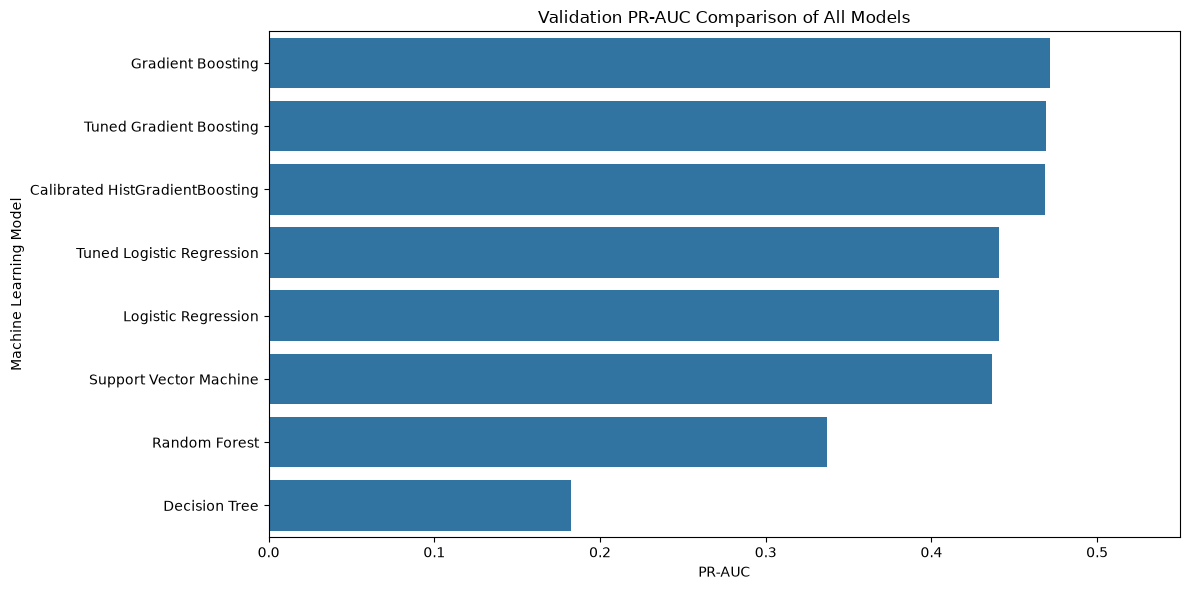

In [175]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=all_model_comparison,
    x="PR-AUC",
    y="Model"
)

plt.title("Validation PR-AUC Comparison of All Models")
plt.xlabel("PR-AUC")
plt.ylabel("Machine Learning Model")
plt.xlim(0, 0.55)
plt.tight_layout()
plt.show()

In [176]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Test different classification thresholds
thresholds = np.arange(0.10, 0.81, 0.05)

threshold_results = []

for threshold in thresholds:

    y_threshold_pred = (
        calibrated_hist_model.predict_proba(X_val_processed)[:, 1]
        >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, y_threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_threshold_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, y_threshold_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-Score
0,0.10,0.1127,1.0000,0.2025
1,0.15,0.1133,0.9899,0.2034
2,0.20,0.1216,0.9555,0.2157
3,0.25,0.1350,0.9124,0.2353
4,0.30,0.1595,0.8851,0.2703
5,0.35,0.1935,0.8017,0.3117
6,0.40,0.2640,0.7184,0.3861
7,0.45,0.3390,0.6624,0.4484
8,0.50,0.3739,0.6264,0.4683
9,0.55,0.4139,0.6149,0.4948


In [177]:
# Find the row with the highest F1-score
best_row = threshold_df.loc[
    threshold_df["F1-Score"].idxmax()
]

# Store the selected threshold
best_threshold = float(best_row["Threshold"])

print("Best Threshold:", best_threshold)
print("Best Precision:", round(best_row["Precision"], 4))
print("Best Recall:", round(best_row["Recall"], 4))
print("Best F1-Score:", round(best_row["F1-Score"], 4))

Best Threshold: 0.6
Best Precision: 0.4397
Best Recall: 0.602
Best F1-Score: 0.5082


In [178]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    classification_report
)

# Predict probabilities on the test dataset
y_test_probabilities = calibrated_hist_model.predict_proba(
    X_test_processed
)[:, 1]

# Apply the selected threshold
y_test_predictions = (
    y_test_probabilities >= best_threshold
).astype(int)

# Calculate final test metrics
final_test_results = {
    "Model": "Calibrated HistGradientBoosting",
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test, y_test_predictions),
    "Precision": precision_score(
        y_test, y_test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_test_predictions, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_test_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_test_probabilities),
    "PR-AUC": average_precision_score(
        y_test, y_test_probabilities
    ),
    "Brier Score": brier_score_loss(
        y_test, y_test_probabilities
    ),
    "Log Loss": log_loss(y_test, y_test_probabilities)
}

final_test_df = pd.DataFrame([final_test_results])

display(final_test_df.round(4))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_predictions,
    target_names=["No Subscription", "Subscription"]
))

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Brier Score,Log Loss
0,Calibrated HistGradientBoosting,0.6,0.8774,0.4664,0.6092,0.5283,0.8165,0.488,0.1575,0.5027


Confusion Matrix:
[[4996  485]
 [ 272  424]]

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.95      0.91      0.93      5481
   Subscription       0.47      0.61      0.53       696

       accuracy                           0.88      6177
      macro avg       0.71      0.76      0.73      6177
   weighted avg       0.89      0.88      0.88      6177



In [179]:
# Create customer ranking using test dataset predictions
customer_ranking = X_test.copy()

# Add actual subscription status
customer_ranking["Actual_Subscription"] = y_test.values

# Add predicted subscription probability
customer_ranking["Subscription_Probability"] = y_test_probabilities

# Add predicted class using selected threshold
customer_ranking["Predicted_Subscription"] = y_test_predictions

# Rank customers from highest to lowest probability
customer_ranking = customer_ranking.sort_values(
    by="Subscription_Probability",
    ascending=False
).reset_index(drop=True)

# Add priority rank
customer_ranking["Priority_Rank"] = (
    customer_ranking.index + 1
)

# Display top 20 customers
display(
    customer_ranking[
        [
            "Priority_Rank",
            "age",
            "job",
            "marital",
            "education",
            "Subscription_Probability",
            "Predicted_Subscription",
            "Actual_Subscription"
        ]
    ].head(20).round(4)
)

,Priority_Rank,age,job,marital,education,Subscription_Probability,Predicted_Subscription,Actual_Subscription
0,1,60,admin.,married,unknown,0.9595,1,1
1,2,70,retired,divorced,high.school,0.9595,1,1
2,3,26,admin.,single,university.degree,0.9592,1,1
3,4,40,technician,married,professional.course,0.9589,1,1
4,5,31,technician,divorced,university.degree,0.9589,1,1
5,6,25,unemployed,married,high.school,0.9589,1,1
6,7,66,housemaid,divorced,basic.4y,0.9584,1,1
7,8,48,admin.,married,university.degree,0.9581,1,1
8,9,33,services,single,high.school,0.9578,1,0
9,10,19,student,single,basic.6y,0.9577,1,1


In [180]:
# Campaign capacity percentages
capacity_percentages = [5, 10, 15, 20, 25, 30]

capacity_results = []

total_customers = len(customer_ranking)
total_actual_subscribers = customer_ranking[
    "Actual_Subscription"
].sum()

for percentage in capacity_percentages:

    # Number of customers the bank can contact
    customers_to_contact = int(
        np.ceil(total_customers * percentage / 100)
    )

    # Select highest-ranked customers
    selected_customers = customer_ranking.head(
        customers_to_contact
    )

    # Count actual subscribers among selected customers
    actual_subscribers = selected_customers[
        "Actual_Subscription"
    ].sum()

    # Calculate response rate and subscriber coverage
    response_rate = (
        actual_subscribers / customers_to_contact
    )

    subscriber_coverage = (
        actual_subscribers / total_actual_subscribers
    )

    capacity_results.append({
        "Call Capacity (%)": percentage,
        "Customers Contacted": customers_to_contact,
        "Actual Subscribers Found": actual_subscribers,
        "Response Rate (%)": response_rate * 100,
        "Subscriber Coverage (%)": subscriber_coverage * 100
    })

capacity_df = pd.DataFrame(capacity_results)

display(capacity_df.round(2))

,Call Capacity (%),Customers Contacted,Actual Subscribers Found,Response Rate (%),Subscriber Coverage (%)
0,5,309,203,65.70,29.17
1,10,618,327,52.91,46.98
2,15,927,426,45.95,61.21
3,20,1236,464,37.54,66.67
4,25,1545,495,32.04,71.12
5,30,1854,519,27.99,74.57


In [181]:
final_project_summary = pd.DataFrame({
    "Category": [
        "Selected Model",
        "Classification Threshold",
        "Test Accuracy",
        "Test Precision",
        "Test Recall",
        "Test F1-Score",
        "Test ROC-AUC",
        "Test PR-AUC",
        "Test Brier Score",
        "Test Log Loss",
        "Best Call Capacity",
        "Response Rate at 5% Capacity",
        "Subscriber Coverage at 20% Capacity"
    ],
    "Result": [
        "Calibrated HistGradientBoosting",
        best_threshold,
        round(final_test_results["Accuracy"], 4),
        round(final_test_results["Precision"], 4),
        round(final_test_results["Recall"], 4),
        round(final_test_results["F1-Score"], 4),
        round(final_test_results["ROC-AUC"], 4),
        round(final_test_results["PR-AUC"], 4),
        round(final_test_results["Brier Score"], 4),
        round(final_test_results["Log Loss"], 4),
        "5% (illustrative capacity choice)",
        "65.70%",
        "66.67%"
    ]
})

display(final_project_summary)

,Category,Result
0,Selected Model,Calibrated HistGradientBoosting
1,Classification Threshold,0.6
2,Test Accuracy,0.8774
3,Test Precision,0.4664
4,Test Recall,0.6092
5,Test F1-Score,0.5283
6,Test ROC-AUC,0.8165
7,Test PR-AUC,0.488
8,Test Brier Score,0.1575
9,Test Log Loss,0.5027


In [182]:
import xgboost
print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1


In [183]:
from xgboost import XGBClassifier
print("XGBoost is ready to use.")

XGBoost is ready to use.


In [184]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative samples:", negative_count)
print("Positive samples:", positive_count)
print("Scale positive weight:", scale_pos_weight)

Negative samples: 25575
Positive samples: 3247
Scale positive weight: 7.876501385894672


In [185]:
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_processed, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [186]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

xgb_val_predictions = xgb_model.predict(X_val_processed)
xgb_val_probabilities = xgb_model.predict_proba(X_val_processed)[:, 1]

xgb_results = {
    "Model": "XGBoost",
    "Accuracy": accuracy_score(y_val, xgb_val_predictions),
    "Precision": precision_score(y_val, xgb_val_predictions, zero_division=0),
    "Recall": recall_score(y_val, xgb_val_predictions, zero_division=0),
    "F1-Score": f1_score(y_val, xgb_val_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, xgb_val_probabilities),
    "PR-AUC": average_precision_score(y_val, xgb_val_probabilities)
}

display(pd.DataFrame([xgb_results]).round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,XGBoost,0.8418,0.379,0.6322,0.4739,0.7935,0.4688


In [187]:
trained_models["XGBoost"] = xgb_model

print("XGBoost added to trained_models.")
print("Available models:", list(trained_models.keys()))

XGBoost added to trained_models.
Available models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'Support Vector Machine', 'XGBoost']


In [188]:
try:
    import catboost
    print("CatBoost is ready to use.")
    print("CatBoost version:", catboost.__version__)
except ImportError:
    print("CatBoost is not installed.")

CatBoost is ready to use.
CatBoost version: 1.2.10


In [189]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

class_weights = [
    1,
    negative_count / positive_count
]

print("Class weights:", class_weights)

Class weights: [1, np.float64(7.876501385894672)]


In [190]:
from catboost import CatBoostClassifier

catboost_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="PRAUC",
    class_weights=class_weights,
    random_seed=42,
    verbose=100
)

catboost_model.fit(
    X_train_processed,
    y_train
)

trained_models["CatBoost"] = catboost_model

print("CatBoost training completed.")
print("CatBoost added to trained_models.")
print("Available models:", list(trained_models.keys()))

0:	learn: 0.8009710	total: 29.5ms	remaining: 14.7s
100:	learn: 0.8322417	total: 1.09s	remaining: 4.31s
200:	learn: 0.8475051	total: 2.37s	remaining: 3.53s
300:	learn: 0.8632845	total: 3.81s	remaining: 2.52s
400:	learn: 0.8750455	total: 4.97s	remaining: 1.23s
499:	learn: 0.8861196	total: 6.09s	remaining: 0us
CatBoost training completed.
CatBoost added to trained_models.
Available models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'Support Vector Machine', 'XGBoost', 'CatBoost']


In [191]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

y_val_pred_cat = catboost_model.predict(X_val_processed)
y_val_prob_cat = catboost_model.predict_proba(X_val_processed)[:, 1]

catboost_results = {
    "Model": "CatBoost",
    "Accuracy": accuracy_score(y_val, y_val_pred_cat),
    "Precision": precision_score(y_val, y_val_pred_cat),
    "Recall": recall_score(y_val, y_val_pred_cat),
    "F1-Score": f1_score(y_val, y_val_pred_cat),
    "ROC-AUC": roc_auc_score(y_val, y_val_prob_cat),
    "PR-AUC": average_precision_score(y_val, y_val_prob_cat)
}

pd.DataFrame([catboost_results]).round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,CatBoost,0.843,0.3817,0.6351,0.4768,0.7903,0.4738


In [192]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import AdaBoostClassifier, ExtraTreesClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight

print("Additional ML algorithms imported successfully!")


Additional ML algorithms imported successfully!


In [193]:

additional_models = {
    "KNN": KNeighborsClassifier(
        n_neighbors=15,
        weights="distance",
        metric="minkowski",
        p=2,
        n_jobs=-1
    ),

    "Gaussian Naive Bayes": GaussianNB(
        var_smoothing=1e-9
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=200,
        learning_rate=0.05,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "LDA": LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    ),

    "MLP Neural Network": MLPClassifier(
        hidden_layer_sizes=(100, 50),
        activation="relu",
        solver="adam",
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=200,
        early_stopping=True,
        random_state=42
    )
}

print("Additional models defined:")
for name in additional_models:
    print(name)


Additional models defined:
KNN
Gaussian Naive Bayes
AdaBoost
Extra Trees
LDA
MLP Neural Network


In [194]:

additional_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

for name, model in additional_models.items():

    print(f"\nTraining {name}...")

    if name == "AdaBoost":
        model.fit(
            X_train_processed,
            y_train,
            sample_weight=additional_sample_weights
        )
    else:
        model.fit(
            X_train_processed,
            y_train
        )

    trained_models[name] = model

    print(f"{name} trained successfully!")

print("\nAll additional models trained!")



Training KNN...
KNN trained successfully!

Training Gaussian Naive Bayes...
Gaussian Naive Bayes trained successfully!

Training AdaBoost...
AdaBoost trained successfully!

Training Extra Trees...
Extra Trees trained successfully!

Training LDA...
LDA trained successfully!

Training MLP Neural Network...
MLP Neural Network trained successfully!

All additional models trained!


In [195]:

additional_results = []

for name, model in additional_models.items():

    y_pred = model.predict(X_val_processed)

    y_prob = model.predict_proba(
        X_val_processed
    )[:, 1]

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_val, y_prob
        ),
        "PR-AUC": average_precision_score(
            y_val, y_prob
        ),
        "Brier Score": brier_score_loss(
            y_val, y_prob
        ),
        "Log Loss": log_loss(
            y_val, y_prob
        )
    }

    additional_results.append(results)

additional_comparison = pd.DataFrame(additional_results)

additional_comparison = additional_comparison.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

print("Additional Model Performance:")
display(additional_comparison.round(4))


Additional Model Performance:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Brier Score,Log Loss
0,MLP Neural Network,0.8990,0.6475,0.2270,0.3362,0.7798,0.4508,0.0790,0.2806
1,LDA,0.8894,0.5131,0.3664,0.4275,0.7833,0.4303,0.0880,0.3278
2,AdaBoost,0.8354,0.3610,0.5991,0.4506,0.7736,0.4012,0.1688,0.5272
3,Gaussian Naive Bayes,0.8239,0.3185,0.4943,0.3874,0.7542,0.3195,0.1638,2.8553
4,KNN,0.8849,0.4812,0.2759,0.3507,0.7465,0.3149,0.0941,1.3230
5,Extra Trees,0.8760,0.4286,0.3017,0.3541,0.7441,0.2946,0.0997,1.1025


In [196]:

all_model_comparison = pd.concat(
    [
        all_model_comparison,
        additional_comparison
    ],
    ignore_index=True
)

all_model_comparison = all_model_comparison.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

print("Complete ML Model Comparison:")
display(all_model_comparison.round(4))


Complete ML Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Brier Score,Log Loss
0,Gradient Boosting,0.9014,0.6593,0.2586,0.3715,0.7935,0.4717,NaN,NaN
1,Tuned Gradient Boosting,0.9009,0.6615,0.2471,0.3598,0.7932,0.4693,NaN,NaN
2,Calibrated HistGradientBoosting,0.8397,0.3739,0.6264,0.4683,0.7946,0.4683,NaN,NaN
3,MLP Neural Network,0.8990,0.6475,0.2270,0.3362,0.7798,0.4508,0.0790,0.2806
4,Tuned Logistic Regression,0.8303,0.3560,0.6250,0.4536,0.7865,0.4409,NaN,NaN
5,Logistic Regression,0.8300,0.3556,0.6264,0.4537,0.7865,0.4406,NaN,NaN
6,Support Vector Machine,0.8995,0.6569,0.2256,0.3358,0.7864,0.4363,NaN,NaN
7,LDA,0.8894,0.5131,0.3664,0.4275,0.7833,0.4303,0.0880,0.3278
8,AdaBoost,0.8354,0.3610,0.5991,0.4506,0.7736,0.4012,0.1688,0.5272
9,Random Forest,0.8674,0.4200,0.4641,0.4410,0.7661,0.3371,NaN,NaN


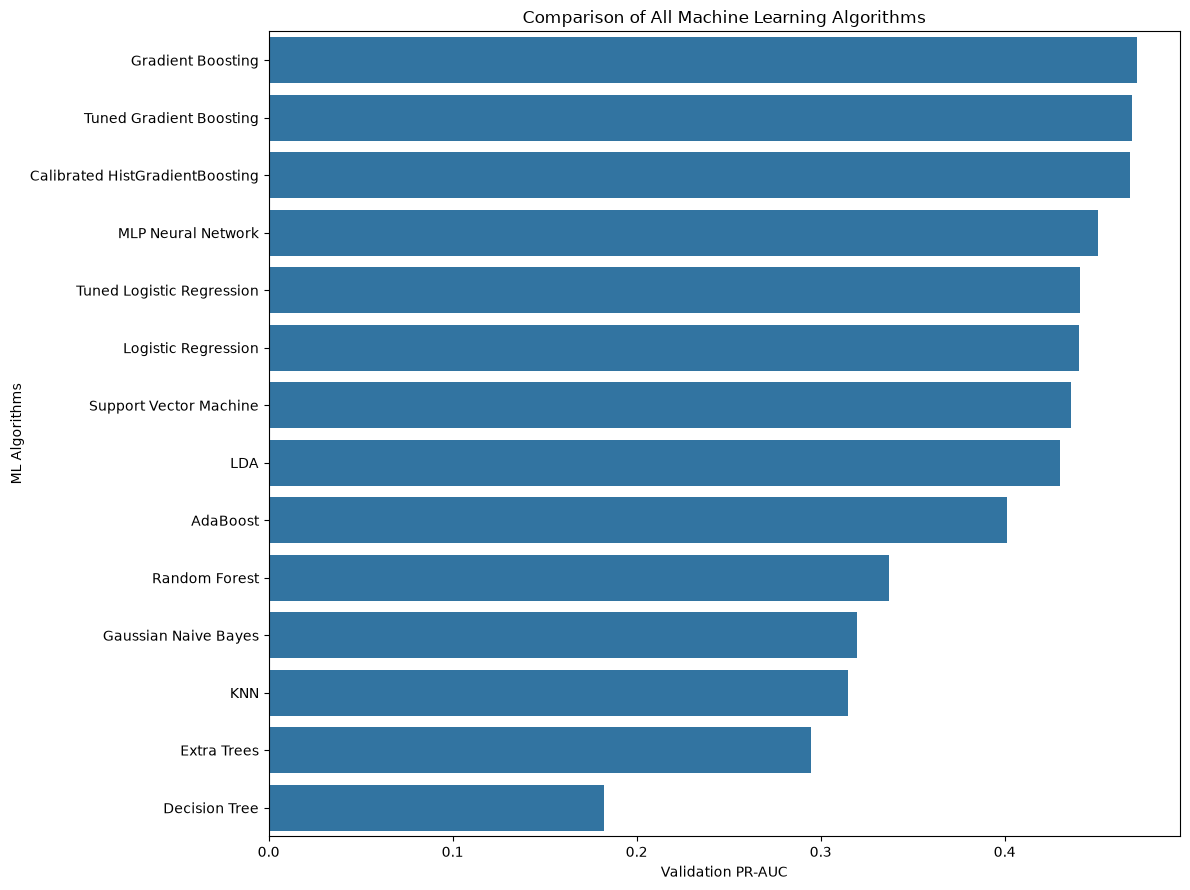

In [197]:

plt.figure(figsize=(12, 9))

sns.barplot(
    data=all_model_comparison,
    x="PR-AUC",
    y="Model"
)

plt.title("Comparison of All Machine Learning Algorithms")
plt.xlabel("Validation PR-AUC")
plt.ylabel("ML Algorithms")
plt.tight_layout()
plt.show()


In [198]:

top_five_models = all_model_comparison.head(5)

print("TOP 5 MACHINE LEARNING MODELS")

display(top_five_models.round(4))

best_model_name = all_model_comparison.iloc[0]["Model"]

print("\nBest model based on validation PR-AUC:")
print(best_model_name)


TOP 5 MACHINE LEARNING MODELS


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Brier Score,Log Loss
0,Gradient Boosting,0.9014,0.6593,0.2586,0.3715,0.7935,0.4717,NaN,NaN
1,Tuned Gradient Boosting,0.9009,0.6615,0.2471,0.3598,0.7932,0.4693,NaN,NaN
2,Calibrated HistGradientBoosting,0.8397,0.3739,0.6264,0.4683,0.7946,0.4683,NaN,NaN
3,MLP Neural Network,0.8990,0.6475,0.2270,0.3362,0.7798,0.4508,0.079,0.2806
4,Tuned Logistic Regression,0.8303,0.3560,0.6250,0.4536,0.7865,0.4409,NaN,NaN



Best model based on validation PR-AUC:
Gradient Boosting


In [199]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

candidate_models = {
    "Gradient Boosting": trained_models["Gradient Boosting"],
    "Tuned Gradient Boosting": best_gradient_model,
    "Calibrated HistGradientBoosting": calibrated_hist_model
}

candidate_probabilities = {}

for name, model in candidate_models.items():

    if name == "Tuned Gradient Boosting":
        probabilities = model.predict_proba(X_val)[:, 1]
    else:
        probabilities = model.predict_proba(X_val_processed)[:, 1]

    candidate_probabilities[name] = probabilities

print("Validation probabilities generated successfully!")

for name, probabilities in candidate_probabilities.items():
    print(name, ":", probabilities.shape)

all_models = trained_models.copy()

all_models["Tuned Logistic Regression"] = best_logistic_model
all_models["Tuned Gradient Boosting"] = best_gradient_model
all_models["Calibrated HistGradientBoosting"] = calibrated_hist_model

complete_results = []

for name, model in all_models.items():

    if hasattr(model, "named_steps"):
        y_pred = model.predict(X_val)
        y_prob = model.predict_proba(X_val)[:, 1]
    else:
        y_pred = model.predict(X_val_processed)
        y_prob = model.predict_proba(X_val_processed)[:, 1]

    complete_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1-Score": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_prob),
        "PR-AUC": average_precision_score(y_val, y_prob),
        "Brier Score": brier_score_loss(y_val, y_prob),
        "Log Loss": log_loss(y_val, y_prob)
    })

all_model_comparison = pd.DataFrame(complete_results)

all_model_comparison = all_model_comparison.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

print("FINAL COMPARISON OF ALL ML MODELS")

display(all_model_comparison.round(4))

print("\nTotal models compared:", len(all_model_comparison))


Validation probabilities generated successfully!
Gradient Boosting : (6177,)
Tuned Gradient Boosting : (6177,)
Calibrated HistGradientBoosting : (6177,)
FINAL COMPARISON OF ALL ML MODELS


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Brier Score,Log Loss
0,CatBoost,0.8430,0.3817,0.6351,0.4768,0.7903,0.4738,0.1470,0.4735
1,Gradient Boosting,0.9014,0.6593,0.2586,0.3715,0.7935,0.4717,0.0771,0.2734
2,Tuned Gradient Boosting,0.9009,0.6615,0.2471,0.3598,0.7932,0.4693,0.0772,0.2737
3,XGBoost,0.8418,0.3790,0.6322,0.4739,0.7935,0.4688,0.1529,0.4914
4,Calibrated HistGradientBoosting,0.8397,0.3739,0.6264,0.4683,0.7946,0.4683,0.1626,0.5151
5,MLP Neural Network,0.8990,0.6475,0.2270,0.3362,0.7798,0.4508,0.0790,0.2806
6,Tuned Logistic Regression,0.8303,0.3560,0.6250,0.4536,0.7865,0.4409,0.1653,0.5241
7,Logistic Regression,0.8300,0.3556,0.6264,0.4537,0.7865,0.4406,0.1654,0.5240
8,Support Vector Machine,0.8995,0.6569,0.2256,0.3358,0.7864,0.4363,0.0796,0.2804
9,LDA,0.8894,0.5131,0.3664,0.4275,0.7833,0.4303,0.0880,0.3278



Total models compared: 16


In [200]:

thresholds = np.arange(0.10, 0.81, 0.05)

threshold_comparison = []

for model_name, probabilities in candidate_probabilities.items():

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        threshold_comparison.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "Accuracy": accuracy_score(y_val, predictions),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1-Score": f1_score(
                y_val, predictions, zero_division=0
            ),
            "Customers Selected (%)": (
                predictions.sum() / len(predictions)
            ) * 100
        })

threshold_comparison_df = pd.DataFrame(
    threshold_comparison
)

display(
    threshold_comparison_df.round(4)
)


,Model,Threshold,Accuracy,Precision,Recall,F1-Score,Customers Selected (%)
0,Gradient Boosting,0.10,0.8279,0.3545,0.6422,0.4568,20.4144
1,Gradient Boosting,0.15,0.8613,0.4188,0.5963,0.4920,16.0434
2,Gradient Boosting,0.20,0.8721,0.4468,0.5675,0.5000,14.3112
3,Gradient Boosting,0.25,0.8800,0.4709,0.5230,0.4956,12.5142
4,Gradient Boosting,0.30,0.8844,0.4861,0.4526,0.4688,10.4905
5,Gradient Boosting,0.35,0.8933,0.5356,0.3994,0.4576,8.4021
6,Gradient Boosting,0.40,0.8969,0.5714,0.3391,0.4256,6.6861
7,Gradient Boosting,0.45,0.9001,0.6172,0.2989,0.4027,5.4557
8,Gradient Boosting,0.50,0.9014,0.6593,0.2586,0.3715,4.4196
9,Gradient Boosting,0.55,0.9021,0.7177,0.2155,0.3315,3.3835


In [201]:

best_threshold_results = (
    threshold_comparison_df.loc[
        threshold_comparison_df.groupby("Model")["F1-Score"].idxmax()
    ]
    .sort_values("F1-Score", ascending=False)
    .reset_index(drop=True)
)

print("BEST THRESHOLD FOR EACH MODEL")

display(best_threshold_results.round(4))


BEST THRESHOLD FOR EACH MODEL


,Model,Threshold,Accuracy,Precision,Recall,F1-Score,Customers Selected (%)
0,Calibrated HistGradientBoosting,0.60,0.8687,0.4397,0.6020,0.5082,15.4282
1,Gradient Boosting,0.20,0.8721,0.4468,0.5675,0.5000,14.3112
2,Tuned Gradient Boosting,0.25,0.8808,0.4742,0.5273,0.4993,12.5304


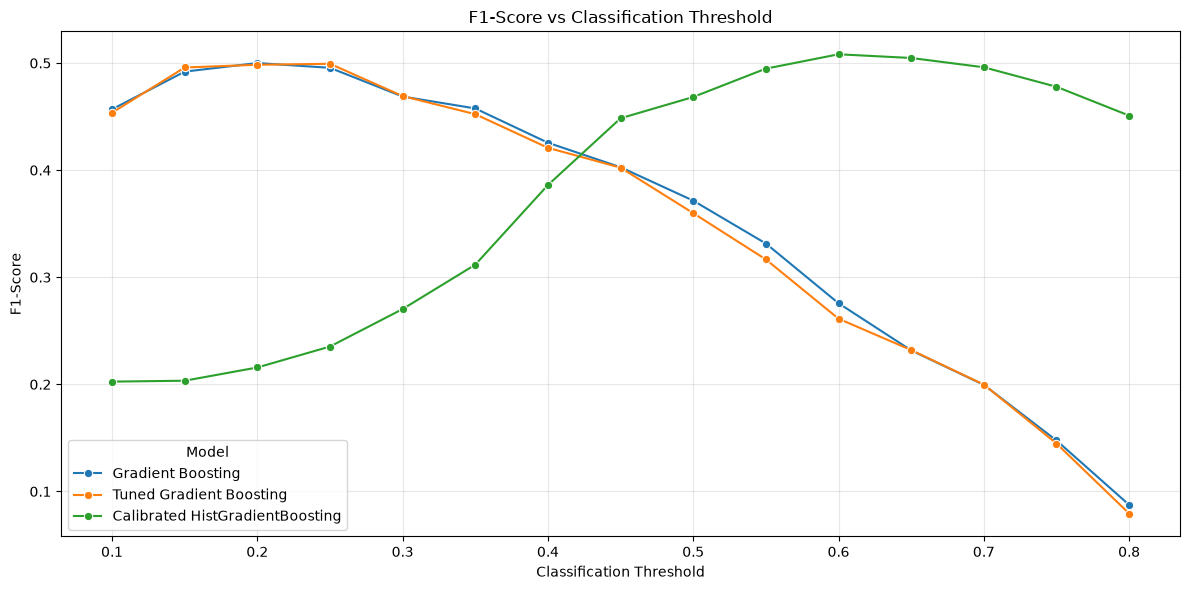

In [202]:

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=threshold_comparison_df,
    x="Threshold",
    y="F1-Score",
    hue="Model",
    marker="o"
)

plt.title("F1-Score vs Classification Threshold")
plt.xlabel("Classification Threshold")
plt.ylabel("F1-Score")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


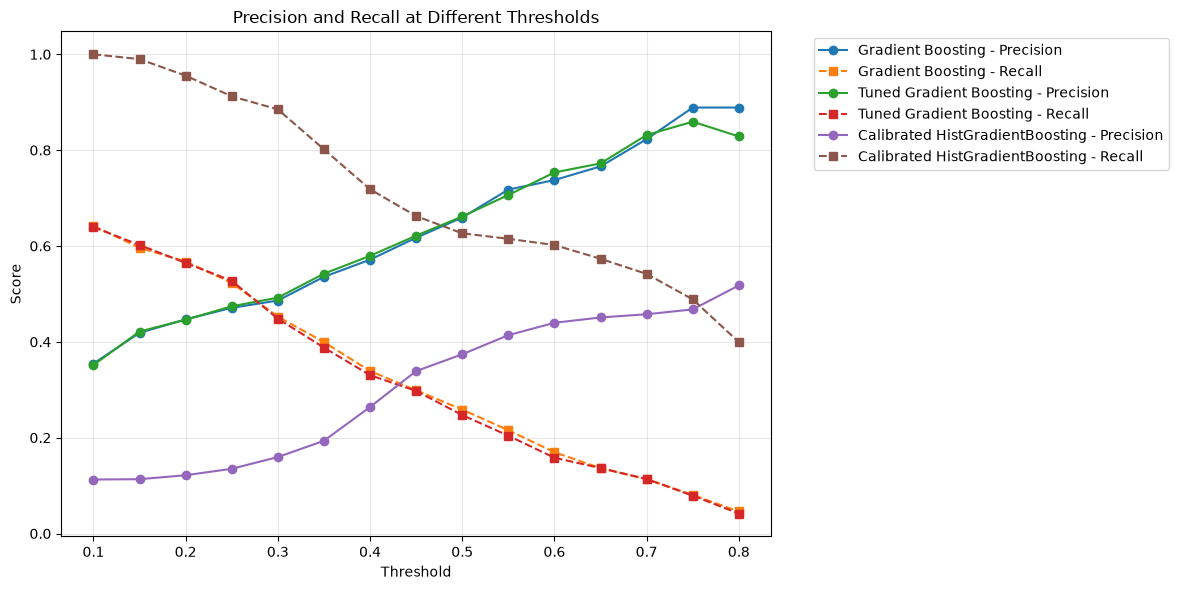

In [203]:

plt.figure(figsize=(12, 6))

for model_name in candidate_models:

    model_data = threshold_comparison_df[
        threshold_comparison_df["Model"] == model_name
    ]

    plt.plot(
        model_data["Threshold"],
        model_data["Precision"],
        marker="o",
        label=f"{model_name} - Precision"
    )

    plt.plot(
        model_data["Threshold"],
        model_data["Recall"],
        marker="s",
        linestyle="--",
        label=f"{model_name} - Recall"
    )

plt.title("Precision and Recall at Different Thresholds")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


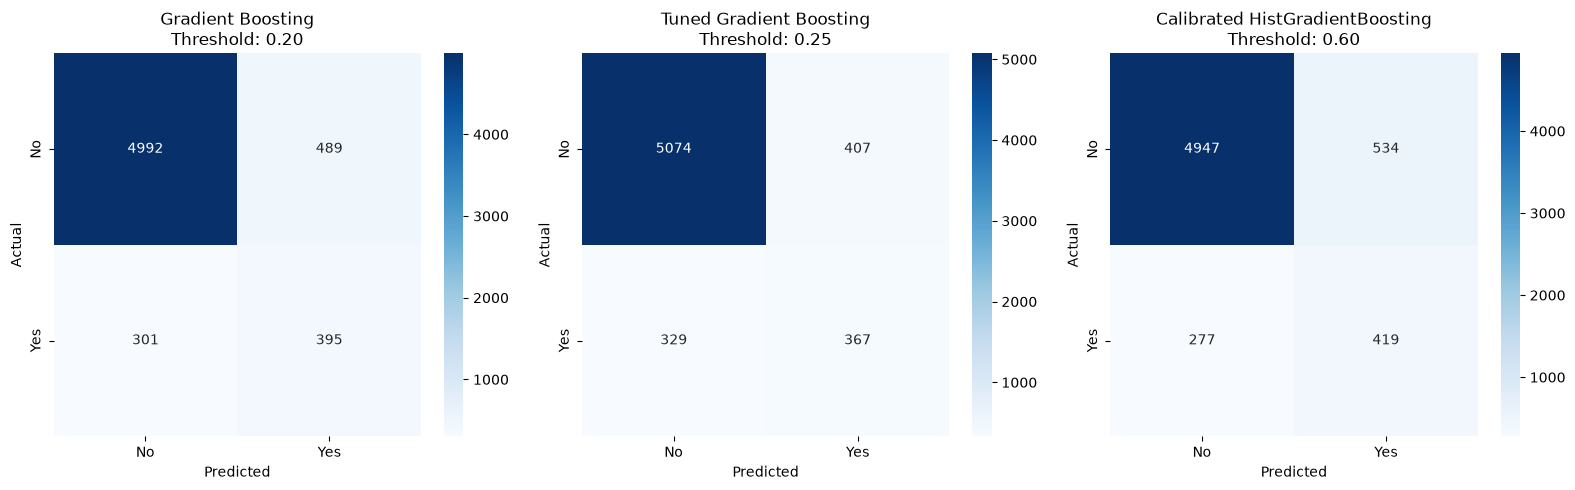

In [204]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (model_name, model) in zip(
    axes,
    candidate_models.items()
):

    best_row = best_threshold_results[
        best_threshold_results["Model"] == model_name
    ].iloc[0]

    threshold = best_row["Threshold"]

    predictions = (
        candidate_probabilities[model_name] >= threshold
    ).astype(int)

    cm = confusion_matrix(y_val, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"],
        ax=ax
    )

    ax.set_title(
        f"{model_name}\nThreshold: {threshold:.2f}"
    )

    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [205]:

ranking_results = []

for model_name, probabilities in candidate_probabilities.items():

    ranking_results.append({
        "Model": model_name,
        "PR-AUC": average_precision_score(
            y_val, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        )
    })

ranking_comparison = pd.DataFrame(
    ranking_results
).sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

display(ranking_comparison.round(4))


,Model,PR-AUC,ROC-AUC
0,Gradient Boosting,0.4717,0.7935
1,Tuned Gradient Boosting,0.4693,0.7932
2,Calibrated HistGradientBoosting,0.4683,0.7946


In [206]:

final_threshold_comparison = best_threshold_results[
    [
        "Model",
        "Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "Customers Selected (%)"
    ]
].merge(
    ranking_comparison,
    on="Model"
)

final_threshold_comparison = final_threshold_comparison.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("FINAL THRESHOLD OPTIMIZATION RESULTS")

display(final_threshold_comparison.round(4))


FINAL THRESHOLD OPTIMIZATION RESULTS


,Model,Threshold,Accuracy,Precision,Recall,F1-Score,Customers Selected (%),PR-AUC,ROC-AUC
0,Calibrated HistGradientBoosting,0.60,0.8687,0.4397,0.6020,0.5082,15.4282,0.4683,0.7946
1,Gradient Boosting,0.20,0.8721,0.4468,0.5675,0.5000,14.3112,0.4717,0.7935
2,Tuned Gradient Boosting,0.25,0.8808,0.4742,0.5273,0.4993,12.5304,0.4693,0.7932


In [207]:

campaign_budgets = [5, 10, 15, 20]

campaign_results = []

actual_positive = np.asarray(y_val).sum()
total_customers = len(y_val)

for model_name, probabilities in candidate_probabilities.items():

    ranked_indices = np.argsort(probabilities)[::-1]

    for budget in campaign_budgets:

        number_to_contact = int(
            np.ceil(total_customers * budget / 100)
        )

        selected_indices = ranked_indices[:number_to_contact]

        actual_subscribers = np.asarray(y_val)[selected_indices].sum()

        precision = actual_subscribers / number_to_contact

        recall = actual_subscribers / actual_positive

        campaign_results.append({
            "Model": model_name,
            "Campaign Budget (%)": budget,
            "Customers Contacted": number_to_contact,
            "Actual Subscribers Found": int(actual_subscribers),
            "Precision (%)": precision * 100,
            "Subscribers Captured (%)": recall * 100
        })

campaign_results_df = pd.DataFrame(campaign_results)

display(campaign_results_df.round(2))


,Model,Campaign Budget (%),Customers Contacted,Actual Subscribers Found,Precision (%),Subscribers Captured (%)
0,Gradient Boosting,5,309,197,63.75,28.30
1,Gradient Boosting,10,618,309,50.00,44.40
2,Gradient Boosting,15,927,406,43.80,58.33
3,Gradient Boosting,20,1236,441,35.68,63.36
4,Tuned Gradient Boosting,5,309,198,64.08,28.45
5,Tuned Gradient Boosting,10,618,303,49.03,43.53
6,Tuned Gradient Boosting,15,927,405,43.69,58.19
7,Tuned Gradient Boosting,20,1236,441,35.68,63.36
8,Calibrated HistGradientBoosting,5,309,199,64.40,28.59
9,Calibrated HistGradientBoosting,10,618,319,51.62,45.83


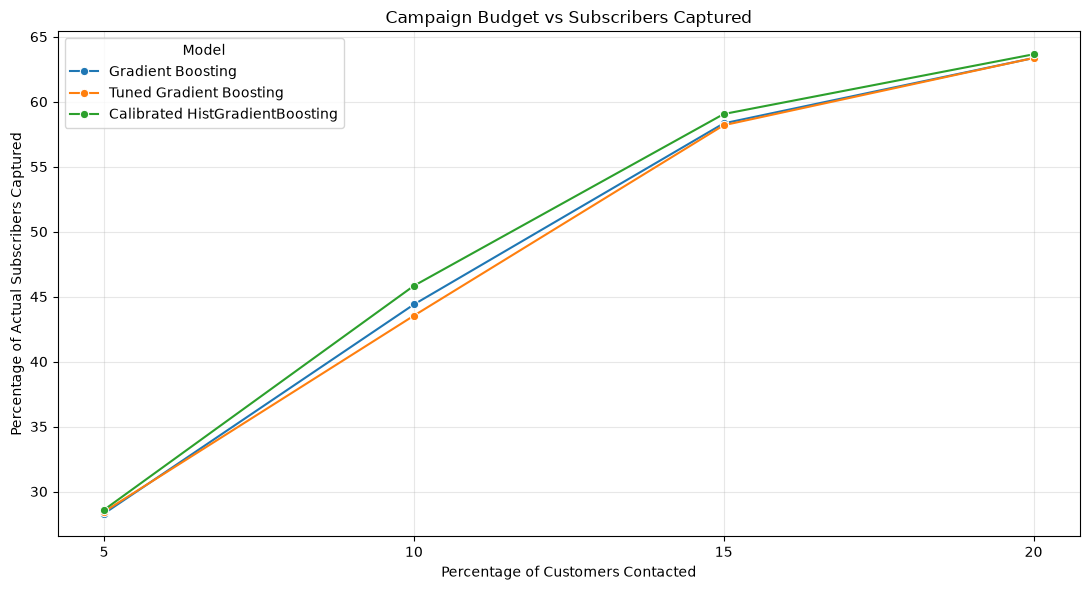

In [208]:

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=campaign_results_df,
    x="Campaign Budget (%)",
    y="Subscribers Captured (%)",
    hue="Model",
    marker="o"
)

plt.title("Campaign Budget vs Subscribers Captured")
plt.xlabel("Percentage of Customers Contacted")
plt.ylabel("Percentage of Actual Subscribers Captured")
plt.xticks(campaign_budgets)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [209]:

fine_thresholds = np.arange(0.55, 0.651, 0.01)

fine_results = []

probabilities = candidate_probabilities[
    "Calibrated HistGradientBoosting"
]

for threshold in fine_thresholds:

    predictions = (
        probabilities >= threshold
    ).astype(int)

    fine_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

fine_threshold_df = pd.DataFrame(fine_results)

display(
    fine_threshold_df.sort_values(
        "F1-Score",
        ascending=False
    ).round(4)
)


,Threshold,Precision,Recall,F1-Score
5,0.60,0.4397,0.6020,0.5082
6,0.61,0.4420,0.5963,0.5076
4,0.59,0.4372,0.6049,0.5075
7,0.62,0.4448,0.5905,0.5074
8,0.63,0.4463,0.5848,0.5062
3,0.58,0.4313,0.6092,0.5051
10,0.65,0.4508,0.5733,0.5047
2,0.57,0.4286,0.6121,0.5041
9,0.64,0.4475,0.5761,0.5038
1,0.56,0.4215,0.6135,0.4997


In [210]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    classification_report
)

y_test_probabilities = calibrated_hist_model.predict_proba(
    X_test_processed
)[:, 1]

y_test_predictions = (
    y_test_probabilities >= 0.60
).astype(int)

final_test_results = {
    "Model": "Calibrated HistGradientBoosting",
    "Threshold": 0.60,
    "Accuracy": accuracy_score(y_test, y_test_predictions),
    "Precision": precision_score(y_test, y_test_predictions),
    "Recall": recall_score(y_test, y_test_predictions),
    "F1-Score": f1_score(y_test, y_test_predictions),
    "ROC-AUC": roc_auc_score(y_test, y_test_probabilities),
    "PR-AUC": average_precision_score(y_test, y_test_probabilities),
    "Brier Score": brier_score_loss(y_test, y_test_probabilities),
    "Log Loss": log_loss(y_test, y_test_probabilities)
}

display(pd.DataFrame([final_test_results]).round(4))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_predictions,
    target_names=["No Subscription", "Subscription"]
))

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Brier Score,Log Loss
0,Calibrated HistGradientBoosting,0.6,0.8774,0.4664,0.6092,0.5283,0.8165,0.488,0.1575,0.5027


Confusion Matrix:
[[4996  485]
 [ 272  424]]

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.95      0.91      0.93      5481
   Subscription       0.47      0.61      0.53       696

       accuracy                           0.88      6177
      macro avg       0.71      0.76      0.73      6177
   weighted avg       0.89      0.88      0.88      6177



In [211]:
import numpy as np
import pandas as pd

campaign_test_results = []

for budget in [5, 10, 15, 20]:
    n_customers = int(len(y_test) * budget / 100)

    top_indices = np.argsort(y_test_probabilities)[::-1][:n_customers]

    actual_subscribers = np.asarray(y_test)[top_indices].sum()
    total_subscribers = np.asarray(y_test).sum()

    campaign_test_results.append({
        "Campaign Budget (%)": budget,
        "Customers Contacted": n_customers,
        "Actual Subscribers Found": int(actual_subscribers),
        "Precision (%)": round(actual_subscribers / n_customers * 100, 2),
        "Subscribers Captured (%)": round(
            actual_subscribers / total_subscribers * 100, 2
        )
    })

campaign_test_df = pd.DataFrame(campaign_test_results)

display(campaign_test_df)

,Campaign Budget (%),Customers Contacted,Actual Subscribers Found,Precision (%),Subscribers Captured (%)
0,5,308,203,65.91,29.17
1,10,617,327,53.00,46.98
2,15,926,426,46.00,61.21
3,20,1235,464,37.57,66.67


In [212]:
for name, obj in list(globals().items()):
    if any(word in name.lower() for word in [
        "preprocess", "transform", "encoder",
        "scaler", "column", "pipeline", "imputer"
    ]):
        print(name, ":", type(obj).__name__)

column : str
columns_to_drop : list
ColumnTransformer : ABCMeta
Pipeline : ABCMeta
SimpleImputer : type
OneHotEncoder : type
StandardScaler : type
numeric_transformer : Pipeline
categorical_transformer : Pipeline
preprocessor : ColumnTransformer
engineered_columns : list
logistic_pipeline : Pipeline
gradient_pipeline : Pipeline


In [213]:
print("Final model:", type(calibrated_hist_model).__name__)
print("Training data shape:", X_train_processed.shape)
print("Test data shape:", X_test_processed.shape)

Final model: CalibratedClassifierCV
Training data shape: (28822, 68)
Test data shape: (6177, 68)


In [215]:
import joblib
import os

os.makedirs("saved_model", exist_ok=True)

model_artifact = {
    "model": calibrated_hist_model,
    "preprocessor": preprocessor,
    "threshold": 0.60,
    "model_name": "Calibrated HistGradientBoosting",
    "engineered_columns": engineered_columns,
    "columns_to_drop": columns_to_drop,
    "feature_count": X_train_processed.shape[1]
}

joblib.dump(model_artifact, "saved_model/banking_campaign_model.pkl")

print("Model and preprocessing saved successfully!")
print("Number of features:", X_train_processed.shape[1])

Model and preprocessing saved successfully!
Number of features: 68


In [216]:
loaded_artifact = joblib.load("saved_model/banking_campaign_model.pkl")

loaded_model = loaded_artifact["model"]

probabilities = loaded_model.predict_proba(X_test_processed[:5])[:, 1]
predictions = (probabilities >= loaded_artifact["threshold"]).astype(int)

print("Model:", loaded_artifact["model_name"])
print("Threshold:", loaded_artifact["threshold"])
print("Probabilities:", probabilities)
print("Predictions:", predictions)

Model: Calibrated HistGradientBoosting
Threshold: 0.6
Probabilities: [0.22779421 0.23179581 0.19396517 0.31234407 0.33496954]
Predictions: [0 0 0 0 0]


In [217]:
import joblib
import os

os.makedirs("saved_model", exist_ok=True)

model_artifact = {
    "model": calibrated_hist_model,
    "preprocessor": preprocessor,
    "threshold": 0.60,
    "model_name": "Calibrated HistGradientBoosting",
    "feature_columns": list(preprocessor.feature_names_in_),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "columns_to_drop": columns_to_drop,
    "engineered_columns": [
        "previously_contacted",
        "previous_campaign_contacted",
        "age_group"
    ],
    "age_bins": [0, 24, 35, 50, 65, np.inf],
    "age_labels": [
        "Young",
        "Young Adult",
        "Adult",
        "Senior",
        "Elderly"
    ]
}

joblib.dump(
    model_artifact,
    "saved_model/banking_campaign_model.pkl"
)

print("Updated model saved successfully!")

Updated model saved successfully!


In [218]:
import pandas as pd
import numpy as np

def prepare_customer_data(raw_data, artifact):

    data = raw_data.copy()

    data["previously_contacted"] = np.where(
        data["pdays"] == 999,
        0,
        1
    )

    data["previous_campaign_contacted"] = np.where(
        data["previous"] > 0,
        1,
        0
    )

    data["age_group"] = pd.cut(
        data["age"],
        bins=artifact["age_bins"],
        labels=artifact["age_labels"]
    )

    data = data.drop(
        columns=artifact["columns_to_drop"],
        errors="ignore"
    )

    expected_columns = artifact["feature_columns"]

    missing_columns = [
        col for col in expected_columns
        if col not in data.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    data = data[expected_columns]

    return data

In [219]:
def predict_customers(raw_data, artifact):

    model = artifact["model"]
    transformer = artifact["preprocessor"]
    threshold = artifact["threshold"]

    prepared_data = prepare_customer_data(
        raw_data,
        artifact
    )

    processed_data = transformer.transform(prepared_data)

    probabilities = model.predict_proba(
        processed_data
    )[:, 1]

    predictions = (probabilities >= threshold).astype(int)

    results = pd.DataFrame({
        "Subscription_Probability": probabilities,
        "Prediction": np.where(
            predictions == 1,
            "Yes",
            "No"
        )
    }, index=raw_data.index)

    results["Priority"] = (
        results["Subscription_Probability"]
        .rank(ascending=False, method="first")
        .astype(int)
    )

    return results.sort_values(
        by="Subscription_Probability",
        ascending=False
    )

In [220]:
loaded_artifact = joblib.load(
    "saved_model/banking_campaign_model.pkl"
)

raw_sample = X_test.drop(
    columns=[
        "previously_contacted",
        "previous_campaign_contacted",
        "age_group"
    ],
    errors="ignore"
).head(5)

results = predict_customers(
    raw_sample,
    loaded_artifact
)

display(results)

,Subscription_Probability,Prediction,Priority
27496,0.334970,No,1
29256,0.312344,No,2
8040,0.231796,No,3
7289,0.227794,No,4
4717,0.193965,No,5


In [221]:
all_results = predict_customers(
    X_test.drop(
        columns=[
            "previously_contacted",
            "previous_campaign_contacted",
            "age_group"
        ],
        errors="ignore"
    ),
    loaded_artifact
)

top_10_percent = all_results.head(
    int(len(all_results) * 0.10)
)

print("Customers selected:", len(top_10_percent))

display(top_10_percent.head(10))

Customers selected: 617


,Subscription_Probability,Prediction,Priority
39648,0.959525,Yes,1
39740,0.959451,Yes,2
39443,0.959157,Yes,3
39646,0.958907,Yes,5
39736,0.958907,Yes,4
39233,0.958899,Yes,6
39349,0.958383,Yes,7
39451,0.958106,Yes,8
39353,0.957832,Yes,9
39147,0.957735,Yes,10


In [224]:
loaded_artifact = joblib.load(
    "saved_model/banking_campaign_model.pkl"
)

print("Model loaded:", loaded_artifact["model_name"])
print("Features expected:", len(loaded_artifact["feature_columns"]))

Model loaded: Calibrated HistGradientBoosting
Features expected: 21


In [225]:
raw_sample = X_test.drop(
    columns=[
        "previously_contacted",
        "previous_campaign_contacted",
        "age_group"
    ],
    errors="ignore"
).head(5)

results = predict_customers(
    raw_sample,
    loaded_artifact
)

display(results)

,Subscription_Probability,Prediction,Priority
27496,0.334970,No,1
29256,0.312344,No,2
8040,0.231796,No,3
7289,0.227794,No,4
4717,0.193965,No,5


In [227]:
all_results = predict_customers(
    X_test.drop(
        columns=[
            "previously_contacted",
            "previous_campaign_contacted",
            "age_group"
        ],
        errors="ignore"
    ),
    loaded_artifact
)

top_10_percent = all_results.head(
    int(len(all_results) * 0.10)
)

print("Total customers:", len(all_results))
print("Customers selected:", len(top_10_percent))

display(top_10_percent.head(10))

Total customers: 6177
Customers selected: 617


,Subscription_Probability,Prediction,Priority
39648,0.959525,Yes,1
39740,0.959451,Yes,2
39443,0.959157,Yes,3
39646,0.958907,Yes,5
39736,0.958907,Yes,4
39233,0.958899,Yes,6
39349,0.958383,Yes,7
39451,0.958106,Yes,8
39353,0.957832,Yes,9
39147,0.957735,Yes,10


In [228]:
print("Prediction summary:")
print(all_results["Prediction"].value_counts())

print("\nAverage subscription probability:")
print(all_results["Subscription_Probability"].mean())

print("\nTop priority customer:")
display(all_results.head(1))

Prediction summary:
Prediction
No     5268
Yes     909
Name: count, dtype: int64

Average subscription probability:
0.38957732960879443

Top priority customer:


,Subscription_Probability,Prediction,Priority
39648,0.959525,Yes,1


In [230]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "fastapi",
    "uvicorn[standard]"
])

0

In [231]:
import fastapi
import uvicorn

print("FastAPI:", fastapi.__version__)
print("Uvicorn:", uvicorn.__version__)
print("Installation successful!")

FastAPI: 0.163.1
Uvicorn: 0.54.0
Installation successful!


In [233]:
import os

print("Current folder:", os.getcwd())
print("Model exists:", os.path.exists("saved_model/banking_campaign_model.pkl"))

Current folder: c:\Users\Gadiga Vaishnavi\Downloads\BANKING_CAMPAIGN\notebooks
Model exists: True


In [232]:
print("Feature columns:")
print(list(preprocessor.feature_names_in_))

print("\nColumns to drop:")
print(columns_to_drop)

print("\nTest data columns:")
print(list(X_test.columns))

Feature columns:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'previous_campaign_contacted', 'age_group']

Columns to drop:
['y', 'target', 'duration', 'campaign', 'campaign_frequency']

Test data columns:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'previous_campaign_contacted', 'age_group']
